# Benchmark construction: provisional map references and query intents

**reference-rules-v1 / query-specification-v1**, pilot **data-pilot-v1**.
This development inspection follows verified data access in
[Data Understanding](01_data_understanding.ipynb). It derives relevance conditions
from native maps, independently of text answers and model scores. Work package 4 adds model-independent coverage, spatial grouping and a bounded
acquisition plan. The benchmark remains **blocked, not frozen**: local archive extraction now reaches the fixed 2,000-ID inventory.
The revised target is generalized map agreement; unknown map judgments
and insufficient hard relation negatives still prevent a freeze.

## 1. What does reference relevance mean?

The source maps contain CLC level-3 codes. Our versioned specification groups
311/312/313 as forest, 511/512 as inland water, 211/212/213 as arable land and
231 as pasture. Other documented CLC codes are known other cover; they do not
become unknown merely because our queries omit them. Unrecognized IDs, masked
NoData and code 999 remain unknown. Map agreement is not independent visual truth.

All class fractions use the **full native patch area**, including unknown pixels.
For known mapped class area $A_c$, unknown area $U$ and total area $A$, evidence
bounds are $a_c^- = A_c/A$ and $a_c^+ = (A_c+U)/A$. Presence is true if
$a_c^- \ge t_c$, false if $a_c^+ < t_c$, and unknown otherwise. Missing maps have
unknown numeric evidence and decisions. A false decision means insufficient
minimum coverage, not necessarily zero mapped area.

Sections 1–10 retain the original v1 assessment. Section 11 adds the explicitly
versioned continuation (`development-validation-v2`, `benchmark-candidate-v2`).
Sections 12–13 preserve the historical 25-ID access assessment. Section 14
reports the full planned selection and independently acquired original texts.

Section 15 reports the explicitly authorized `benchmark-design-v2` estimand
and the one fixed expansion, preserving earlier scientific checkpoints.


## 2. Configuration: which choices are provisional?

We use **5% full-patch coverage per class** and **60 m summed shared boundary**.
Five percent avoids giving isolated pixels the same presence status as substantial
mapped cover; 60 m requires more than a single 10-m edge. These are illustrative
development choices, not empirically validated optima or a final parameter freeze.
Larger development coverage and reference plausibility checks remain necessary.

Adjacency uses horizontal/vertical cell neighbors only. Each undirected edge is
counted once, using native edge length in projected metres. Diagonal corner contact
has zero shared boundary. Both presence conditions and sufficient total boundary
must hold. Unknown-compatible edges provide a conservative upper bound, which
may not be jointly attainable. A conjunction is false if any necessary condition
is false, unknown if unresolved, and true only if all conditions are true.

The [original BigEarthNet.txt paper, §3.1](https://arxiv.org/html/2603.29630v2#S3.SS1)
mentions pairwise adjacency without confirming this four-neighbor/60-m definition.
This notebook uses **our derived rule**. It does not equate adjacency with distance
or borrow text answers as reference labels.

In [1]:
import hashlib
import json
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

from earth_observation.benchmark import (
    coverage_tables,
    freeze_blockers,
    load_benchmark_record,
    select_catalog,
    spatial_split,
    verified_footprints,
)
from earth_observation.encoding import file_digest
from earth_observation.raster import inspect_patch, load_rgb, patch_files
from earth_observation.reference import evaluate_pilot, load_specifications
from earth_observation.validation import validate_development_sources

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RULES_PATH = ROOT / "config/reference-rules-v1.json"
QUERIES_PATH = ROOT / "config/query-specification-v1.json"
MANIFEST_PATH = ROOT / "manifests/data-pilot-v1.json"
CACHE = ROOT / "data/cache"
RAW = ROOT / "data/raw"
EXAMPLE_INDICES = [
    0,
    1,
    2,
]  # Fixed positions illustrating absence, threshold and contact.
DISPLAY_UPPER_DN = 3000
DESIGN_PATH = ROOT / "config/benchmark-design-v1.json"
CANDIDATE_PATH = ROOT / "manifests/benchmark-candidate-v1.json"
DESIGN = json.loads(DESIGN_PATH.read_text())
VALIDATION_MANIFEST = ROOT / "manifests/development-validation-v2.json"
CURRENT_CANDIDATE = ROOT / "manifests/benchmark-candidate-v2.json"
NEW_EXAMPLE_POSITIONS = [10, 11, 12]  # Predeclared extra development batch.
ARCHIVE_ACCESS_PATH = ROOT / "manifests/archive-data-access-v1.json"
COMPLETION_PATH = ROOT / "outputs/archive-data-access-v1/completion.json"
ARCHIVE_EXAMPLE_POSITIONS = [0, 1, 2]  # First three fixed acquisition positions.
FULL_ACCESS_PATH = ROOT / "manifests/archive-data-access-v2.json"
FULL_OUTPUT = ROOT / "outputs/archive-data-access-v2"
FULL_CANDIDATE = ROOT / "manifests/benchmark-candidate-v3.json"
DEV_EXAMPLE_COUNTRIES = ["Austria", "Belgium", "Finland"]
EXPANSION_DESIGN_PATH = ROOT / "config/benchmark-design-v2.json"
EXPANSION_ACCESS_PATH = ROOT / "manifests/archive-data-access-v3.json"
EXPANSION_OUTPUT = ROOT / "outputs/archive-data-access-v3"
EXPANSION_CANDIDATE_PATH = ROOT / "manifests/benchmark-candidate-v4.json"
plt.rcParams["figure.dpi"] = 80
COLORS = {
    "forest": "#238b45",
    "inland_water": "#3182bd",
    "arable_land": "#fee08b",
    "pasture": "#a6d96a",
}

rules, queries = load_specifications(RULES_PATH, QUERIES_PATH)
summaries, decisions = evaluate_pilot(MANIFEST_PATH, CACHE, RAW, rules, queries)
catalog = pd.read_parquet(CACHE / "metadata.parquet")
assert decisions.shape == (10, 8)
pd.DataFrame(
    [
        {
            "concept": name,
            "source_codes": definition["codes"],
            "minimum_fraction": definition["presence_fraction"],
        }
        for name, definition in rules["classes"].items()
    ]
)

FROZEN_DESIGN_PATH = ROOT / "config/benchmark-design-v3.json"
ANALYSIS_PROTOCOL_PATH = ROOT / "config/analysis-protocol-v1.json"
FROZEN_BENCHMARK_PATH = ROOT / "manifests/benchmark-freeze-v1.json"


For these 10-m grids, each cell covers 100 m² and each full patch covers
1,440,000 m². A 5% threshold therefore means at least 72,000 m² of mapped concept
coverage. No raster has been resampled; metre units and native orientation are
validated by the reusable implementation. Unknown area remains in the denominator.

In [2]:
patch_ids = decisions.index.tolist()
area_table = pd.DataFrame([
    {"patch": "_".join(patch_id.rsplit("_", 2)[1:]),
     "unknown_m2": summary["unknown_area_m2"],
     **{name + "_fraction": value["fraction_lower"]
        for name, value in summary["classes"].items()}}
    for patch_id, summary in summaries.items()
])
area_table.round(4)

,patch,unknown_m2,forest_fraction,inland_water_fraction,arable_land_fraction,pasture_fraction
0,26_57,0.0,0.4285,0.0000,0.4913,0.0801
1,27_55,0.0,0.2509,0.0424,0.7067,0.0000
2,27_56,0.0,0.8774,0.0983,0.0243,0.0000
3,27_57,0.0,0.7331,0.1073,0.0000,0.0000
4,27_58,0.0,0.5881,0.0867,0.0000,0.0000
5,27_59,0.0,0.5028,0.0849,0.0000,0.0982
6,27_60,0.0,0.7609,0.1006,0.0000,0.1072
7,27_61,0.0,0.3351,0.0394,0.0000,0.4294
8,28_55,0.0,0.3147,0.1005,0.4008,0.1840
9,28_56,0.0,0.9367,0.0453,0.0000,0.0180


All ten maps have zero unknown area and no unexpected codes. Lower and upper
bounds therefore coincide here; controlled tests, rather than this complete-map
pilot, exercise partial and missing evidence. The sample is one Austria tile and
retains the provider's `test` split. It is a technical/development inspection,
not our future held-out benchmark. These inspected patches cannot establish final
coverage or be treated as an untouched final test after selection decisions.

## 3. Which intents share one reference condition and one direct family?

Eight stable intents cover singles, conjunctions and adjacency, each with three
English formulations (24 texts, **eight intent conditions**). The forest/water
family contains its two singles, conjunction and adjacency; the arable/pasture
family has the analogous four members. Each intent belongs to exactly one family,
set before any model result. Families preserve direct dependence for later paired
statistical analysis, but two families are insufficient for a broad uncertainty
claim. No statistical resampling is implemented here.

Paraphrases express the same condition; none adds quantity, direction, distance,
or a stricter spatial assertion. Numeric thresholds define our map operationalization
and are shared by all paraphrases of the intent.

In [3]:
pd.DataFrame([
    {"intent_id": i["intent_id"], "family_id": i["family_id"],
     "condition": i["kind"] + ": " + ", ".join(i["classes"]),
     "example_text": i["paraphrases"][0], "paraphrases": len(i["paraphrases"])}
    for i in queries["intents"]
])

,intent_id,family_id,condition,example_text,paraphrases
0,single-forest,forest-water,single: forest,A satellite scene containing forest.,3
1,single-inland-water,forest-water,single: inland_water,A satellite scene containing inland water.,3
2,single-arable-land,arable-pasture,single: arable_land,A satellite scene containing arable land.,3
3,single-pasture,arable-pasture,single: pasture,A satellite scene containing pasture.,3
4,both-forest-water,forest-water,"conjunction: forest, inland_water",A satellite scene containing both forest and i...,3
5,adjacent-forest-water,forest-water,"adjacency: forest, inland_water",A satellite scene where forest is adjacent to ...,3
6,both-arable-pasture,arable-pasture,"conjunction: arable_land, pasture",A satellite scene containing both arable land ...,3
7,adjacent-arable-pasture,arable-pasture,"adjacency: arable_land, pasture",A satellite scene where arable land is adjacen...,3


## 4. Does the small pilot cover positive and negative conditions?

Evaluate every patch once per intent, retaining true/false/unknown. Count absence
of coverage explicitly. Also examine adjacency among candidates satisfying both
presence conditions: ordinary negatives caused by a missing/insufficient class
cannot demonstrate that the relation itself distinguishes scenes.

In [4]:
coverage = pd.DataFrame([
    {"intent_id": i["intent_id"], "family_id": i["family_id"],
     **{state: int((decisions[i["intent_id"]] == state).sum())
        for state in ["true", "false", "unknown"]}}
    for i in queries["intents"]
]).set_index("intent_id")
display(coverage)

relation_control_coverage = []
for family in queries["families"]:
    both = decisions["both-" + family] == "true"
    adjacent = decisions.loc[both, "adjacent-" + family]
    relation_control_coverage.append({"family": family, "both_present": int(both.sum()),
                                     "adjacent_true": int((adjacent == "true").sum()),
                                     "adjacent_false": int((adjacent == "false").sum()),
                                     "adjacent_unknown": int((adjacent == "unknown").sum())})
pd.DataFrame(relation_control_coverage)

,family_id,true,false,unknown
intent_id,,,,
single-forest,forest-water,10,0,0
single-inland-water,forest-water,6,4,0
single-arable-land,arable-pasture,3,7,0
single-pasture,arable-pasture,5,5,0
both-forest-water,forest-water,6,4,0
adjacent-forest-water,forest-water,6,4,0
both-arable-pasture,arable-pasture,2,8,0
adjacent-arable-pasture,arable-pasture,2,8,0


,family,both_present,adjacent_true,adjacent_false,adjacent_unknown
0,forest-water,6,6,0,0
1,arable-pasture,2,2,0,0


Forest has ten positives and **no negative**. The other single conditions
have both states. Forest/water conjunction and adjacency each have six positives;
arable/pasture each have two. There are no unknown decisions in this complete-map
sample. Among patches passing both presences, every relation is true: **no hard
relation negative exists for either pair**. Thus this pilot cannot isolate an
adjacency failure from a presence failure. We report that limitation without
retuning thresholds to manufacture a distinction.

## 5. What do the map conditions look like beside real RGB?

The next display uses fixed pilot positions 1–3. RGB uses fixed raw DN/3000 scaling
and source NoData masks, independently of future model preprocessing. Colors on
the right display the four canonical concept masks from the reference calculation,
with known other cover in gray and unknown in white. This display aggregation
follows the explicit mapping; it does not add or interpolate reference labels.
Native projected extents and nearest-neighbor rendering preserve orientation.
Calculated percentages use full area, and boundary metres are summed cell edges.

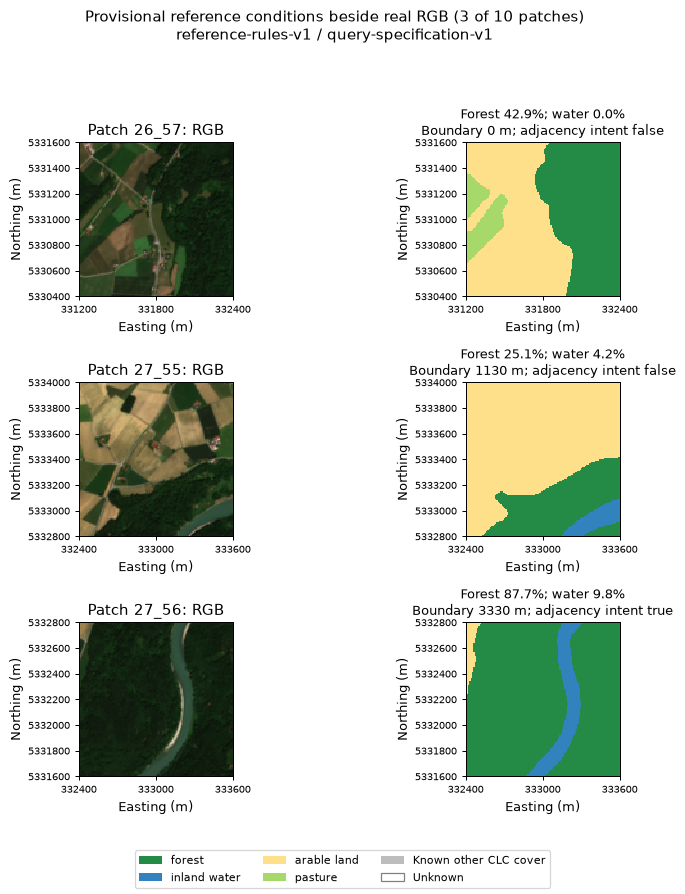

,patch,forest_fraction,water_fraction,boundary_m,adjacency_reference
0,26_57,0.428542,0.000000,0.0,false
1,27_55,0.250903,0.042431,1130.0,false
2,27_56,0.877431,0.098264,3330.0,true


In [5]:
class_names = list(rules["classes"])
cmap = ListedColormap([COLORS[name] for name in class_names] + ["#bdbdbd", "#ffffff"])
norm = BoundaryNorm(np.arange(7) - .5, 6)
fig, axes = plt.subplots(3, 2, figsize=(9, 10), dpi=90)
example_rows = []
for row, index in enumerate(EXAMPLE_INDICES):
    patch_id = patch_ids[index]
    summary = summaries[patch_id]
    files = patch_files(patch_id, RAW / "BigEarthNet-S2", RAW / "Reference_Maps")
    left, bottom, right, top = inspect_patch(files)["rasters"]["B04"]["bounds"]
    extent = (left, right, bottom, top)
    axes[row, 0].imshow(load_rgb(files, upper=DISPLAY_UPPER_DN),
                        extent=extent, interpolation="nearest")
    display_map = np.full(summary["unknown_mask"].shape, 4)
    for color_index, name in enumerate(class_names):
        display_map[summary["class_masks"][name]] = color_index
    display_map[summary["unknown_mask"]] = 5
    axes[row, 1].imshow(display_map, cmap=cmap, norm=norm,
                        extent=extent, interpolation="nearest")
    suffix = "_".join(patch_id.rsplit("_", 2)[1:])
    forest = summary["classes"]["forest"]["fraction_lower"]
    water = summary["classes"]["inland_water"]["fraction_lower"]
    boundary = summary["pairs"][("forest", "inland_water")]["boundary_lower_m"]
    state = decisions.loc[patch_id, "adjacent-forest-water"]
    axes[row, 0].set_title(f"Patch {suffix}: RGB")
    axes[row, 1].set_title(f"Forest {forest:.1%}; water {water:.1%}\n"
                          f"Boundary {boundary:.0f} m; adjacency intent {state}", fontsize=10)
    for ax in axes[row]:
        ax.set(xlabel="Easting (m)", ylabel="Northing (m)")
        ax.ticklabel_format(style="plain", useOffset=False)
        ax.tick_params(labelsize=8)
        ax.set_xticks(np.linspace(left, right, 3))
    example_rows.append({"patch": suffix, "forest_fraction": forest,
                         "water_fraction": water, "boundary_m": boundary,
                         "adjacency_reference": state})
fig.legend(handles=[Patch(facecolor=COLORS[name], label=name.replace("_", " "))
                    for name in class_names] +
                   [Patch(facecolor="#bdbdbd", label="Known other CLC cover"),
                    Patch(facecolor="#ffffff", edgecolor="gray", label="Unknown")],
           loc="lower center", ncol=3, fontsize=9)
fig.suptitle("Provisional reference conditions beside real RGB (3 of 10 patches)\n"
             "reference-rules-v1 / query-specification-v1", fontsize=12)
fig.tight_layout(rect=(0, .07, 1, .94))
(ROOT / "outputs").mkdir(exist_ok=True)
fig.savefig(ROOT / "outputs/reference-pilot-v1-examples.png", dpi=110)
plt.show()
pd.DataFrame(example_rows)

Patch 26_57 has no mapped inland water, so the forest/water intent is false.
Patch 27_55 has mapped water and 1,130 m of forest/water boundary, but water covers
only about 4.24%; its 5% presence condition fails. Patch 27_56 has about 9.83% water
and 3,330 m of mapped boundary, satisfying both presence and contact requirements.
These outcomes follow our specified thresholds, not a claim that RGB alone
proves those quantities. Visual inspection supports broad spatial correspondence: fields and woodland
in the first two scenes, and a river corridor through woodland in the third.
Smaller field boundaries and the riverbank/road corridor are more detailed in RGB
than in the map. The threshold-driven negative for patch 27_55 remains negative
even though water is visibly plausible. No visual inspection independently
verifies exact forest class membership, cover percentages or every boundary.

## 6. Which geographic evidence can we actually separate?

Country and tile names describe the source population, but do not establish
cross-tile overlap or distances. We use the verified native raster footprints,
transform densified bounds to the European metric CRS EPSG:3035, and group any
footprints whose envelope distance is **at most 2,000 m**. Connected components
include transitive chains and repeated acquisitions regardless of date. Envelopes
are conservative; grouping may retain more images together than precise polygons.
The buffer exceeds a 1,200-m patch edge and reduces immediate-neighborhood leakage;
it is not a demonstrated statistical independence distance.

All already inspected/encoded pilot IDs anchor their whole component in
**development**. Other verified components would be assigned by a fixed SHA-256
hash and 0.5 test fraction, without label-based balancing. Unverified selections
remain unassigned. Country, provider split, date or a random patch-ID split cannot
replace this spatial check.

available_images            10
countries                    1
MGRS_tiles                   1
acquisition_dates            1
identical_native_pairs       0
overlapping_native_pairs     0
spatial_components           1
development_images          10
held_out_test_images         0
dtype: int64

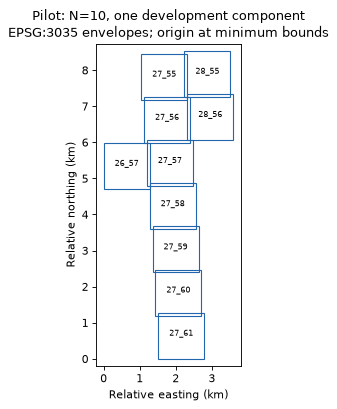

In [6]:
footprints = verified_footprints(patch_ids, RAW)
assignment = spatial_split(footprints, patch_ids, DESIGN["spatial"])
assert assignment.split.eq("development").all()
assert assignment.groupby("group_id").split.nunique().eq(1).all()
available_catalog = catalog.set_index("patch_id").loc[patch_ids]
# Native overlap audit is specific to this available single-CRS pilot.
assert footprints.native_crs.nunique() == 1
native_boxes = footprints.native_bounds.tolist()
identical_pairs = sum(a == b for a, b in combinations(native_boxes, 2))
overlapping_pairs = sum(max(a[0], b[0]) < min(a[2], b[2]) and
                        max(a[1], b[1]) < min(a[3], b[3])
                        for a, b in combinations(native_boxes, 2))
geography = pd.Series({"available_images": len(patch_ids),
                       "countries": available_catalog.country.nunique(),
                       "MGRS_tiles": footprints.tile.nunique(),
                       "acquisition_dates": footprints.date.nunique(),
                       "identical_native_pairs": identical_pairs,
                       "overlapping_native_pairs": overlapping_pairs,
                       "spatial_components": assignment.group_id.nunique(),
                       "development_images": int(assignment.split.eq("development").sum()),
                       "held_out_test_images": int(assignment.split.eq("test").sum())})
display(geography)
fig_geo, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
origin_x, origin_y = footprints.left.min(), footprints.bottom.min()
for pid, row in footprints.iterrows():
    ax.add_patch(plt.Rectangle(((row.left-origin_x)/1000, (row.bottom-origin_y)/1000),
                              (row.right-row.left)/1000, (row.top-row.bottom)/1000,
                              fill=False, edgecolor="#2166ac"))
    ax.text(((row.left+row.right)/2-origin_x)/1000,
            ((row.bottom+row.top)/2-origin_y)/1000,
            "_".join(pid.split("_")[-2:]), ha="center", fontsize=7)
ax.set_xlim(-.2, (footprints.right.max()-origin_x)/1000+.2)
ax.set_ylim(-.2, (footprints.top.max()-origin_y)/1000+.2)
ax.set_aspect("equal")
ax.set_xlabel("Relative easting (km)")
ax.set_ylabel("Relative northing (km)")
ax.set_title("Pilot: N=10, one development component\nEPSG:3035 envelopes; origin at minimum bounds")
plt.show()

All ten verified images lie in one connected component, one Austria tile and one
acquisition date, with zero identical native footprints or positive-area
native overlaps. Immediate neighbors still share landscape context. Moving any of these images to a final test set would split the
same development landscape across stages. The geographic diagram displays
projected bounding envelopes, not a more accurate land-cover map.

### 6.1 How do intent families and relation controls change the counts?

Families summarize **patch × intent decisions**, not independent images or
paraphrases. Every intent uses all ten main candidates. The controls below are
separate, explicitly filtered additional experiments: both class-presence
conditions must be true. Missing classes are not false spatial relations.
Unknown presence is reported outside eligibility; unknown relation remains
inside an eligible control. Unknown source causes are counted separately because
unknown pixels do not always make an intent undecidable.

In [7]:
intent_coverage, family_coverage, relation_coverage, control_ids = coverage_tables(
    decisions, queries, assignment.group_id)
display(intent_coverage)
display(family_coverage.assign(countries=geography["countries"],
                               spatial_components=geography["spatial_components"]))
display(relation_coverage)
candidate = load_benchmark_record(CANDIDATE_PATH, ROOT, require_frozen=False)
unknown_sources = pd.DataFrame(candidate["unknown_pixel_sources"])
display(unknown_sources[["missing_map", "masked_nodata_pixels",
                         "configured_unknown_pixels", "unexpected_code_pixels"]].sum()
        .rename("available-source totals"))

,family_id,true,false,unknown,judged_fraction,spatial_groups,positive_groups,negative_groups,positive_outside_largest_group,negative_outside_largest_group
intent_id,,,,,,,,,,
single-forest,forest-water,10,0,0,1.0,1,1,0,0,0
single-inland-water,forest-water,6,4,0,1.0,1,1,1,0,0
single-arable-land,arable-pasture,3,7,0,1.0,1,1,1,0,0
single-pasture,arable-pasture,5,5,0,1.0,1,1,1,0,0
both-forest-water,forest-water,6,4,0,1.0,1,1,1,0,0
adjacent-forest-water,forest-water,6,4,0,1.0,1,1,1,0,0
both-arable-pasture,arable-pasture,2,8,0,1.0,1,1,1,0,0
adjacent-arable-pasture,arable-pasture,2,8,0,1.0,1,1,1,0,0


,true,false,unknown,patch_intent_count,judged_fraction,unique_images,countries,spatial_components
family_id,,,,,,,,
forest-water,28,12,0,40,1.0,10,1,1
arable-pasture,12,28,0,40,1.0,10,1,1


,family_id,both_present,missing_class,unknown_presence,true,false,unknown,judged_fraction,spatial_groups,true_outside_largest_group,false_outside_largest_group
intent_id,,,,,,,,,,,
adjacent-forest-water,forest-water,6,4,0,6,0,0,1.0,1,0,0
adjacent-arable-pasture,arable-pasture,2,8,0,2,0,0,1.0,1,0,0


missing_map                  0
masked_nodata_pixels         0
configured_unknown_pixels    0
unexpected_code_pixels       0
Name: available-source totals, dtype: int64

The forest/water family has 28 positive and 12 negative patch-intent decisions;
arable/pasture has 12 and 28. Each family still sees only **ten unique images** in
one geographic component. All source masks/configured unknown codes/unrecognized
codes count zero here; all intent judgments are known. Controlled tests exercise
unknown source causes and ambiguous states, rather than inventing them in this
complete-map pilot. The six forest/water and two arable/pasture control candidates
have zero false relations. After removing the largest positive component,
**zero positives remain for every intent**.

## 7. Which reference-based requirements are necessary before freeze?

The versioned design requires at least 20 main candidates, ten positives and ten
negatives per fixed intent, three spatial components, and ten positives after
removing the largest positive component. Ten positives prevent a structural P@10
ceiling below one; negatives and N>10 prevent an all-positive or prevalence-only
task. Cluster removal requires dispersed evidence, not a power guarantee.

Each both-present relation control requires ten true and ten false relations,
three components, and five true/five false cases outside their respective largest
components. A presence-negative image cannot substitute for a relation-negative.
All judgments must be known for the complete main metric comparison, matching the
existing conservative metric contract. Unknown candidates are retained in rankings,
with main metrics undefined and separately named judged-only diagnostics; no
query-dependent reference filtering repairs the main collection.

These criteria were specified from development/reference limitations before any
new test reference inspection and without model scores. The existing 5%/60-m
semantics and 24 texts remain unchanged and provisional. No final test, semantic
retuning or model evaluation occurs here.

In [8]:
development_failures = freeze_blockers(intent_coverage, relation_coverage,
                                     DESIGN["coverage"], 0, queries)
display(pd.DataFrame({"development_gate_failure": development_failures}))
print("These failures describe development feasibility; there is no held-out test coverage yet.")

,development_gate_failure
0,single-forest: candidate count 10 < 20
1,single-forest: negatives 0 < 10
2,single-forest: positive dispersion 0 < 10
3,single-forest: spatial groups 1 < 3
4,single-inland-water: candidate count 10 < 20
5,single-inland-water: positives 6 < 10
6,single-inland-water: negatives 4 < 10
7,single-inland-water: positive dispersion 0 < 10
8,single-inland-water: spatial groups 1 < 3
9,single-arable-land: candidate count 10 < 20


These failures describe development feasibility; there is no held-out test coverage yet.


## 8. Can a bounded expansion reach a spatially broader inventory?

The pinned official clean catalog contains 480,038 patches across ten countries
and 54 MGRS tiles; its quality exclusions belong to the source population. The
predeclared rule selects **25 per country, 250 total**, spreading quotas across
SHA-256-ordered tiles and patches. The entire previously developed tile `33UUP`
is excluded. No land-cover label, caption or model result is read by sampling.
Equal-country quotas are deliberate enrichment, not population-proportional
sampling. Actual native geometry is still required before assigning splits.

The acquisition plan permits batches of 25 and a 64-MiB additional raster cap.
We do not replace inaccessible IDs with convenient early members, download full
archives, or grow indefinitely. The table below is an acquisition plan,
**not 250 downloaded/validated images**.

In [9]:
planned = select_catalog(catalog, DESIGN["selection"])
pd.testing.assert_frame_equal(planned, pd.read_csv(ROOT / "manifests/coverage-selection-v1.csv"))
display(planned.groupby("country").agg(planned_images=("patch_id", "size"),
                                       MGRS_tiles=("tile", "nunique")))
print(f"Selected {len(planned)} IDs across {planned.tile.nunique()} distinct tiles.")
access = json.loads((ROOT / "manifests/coverage-access-v1.json").read_text())
display(pd.DataFrame(access["inventory"]))
display(pd.DataFrame(access["tail_probes"])[["name", "size_bytes", "seekable_zstd_footer_present"]])
display(pd.Series(candidate["access"], name="verified access assessment"))

,planned_images,MGRS_tiles
country,,
Austria,25,7
Belgium,25,3
Finland,25,21
Ireland,25,5
Kosovo,25,1
Lithuania,25,7
Luxembourg,25,1
Portugal,25,3
Serbia,25,6


Selected 250 IDs across 53 distinct tiles.


,name,size_bytes
0,BigEarthNet-S1.tar.zst,54439153171
1,metadata.parquet,3616349
2,metadata_for_patches_with_snow_cloud_or_shadow...,710162
3,Reference_Maps.tar.zst,282391301
4,BigEarthNet-S2.tar.zst,63251710377


,name,size_bytes,seekable_zstd_footer_present
0,s2-tail-1024.bin,1024,False
1,maps-tail-1024.bin,1024,False


planned_count                       250
planned_tiles                        53
verified_new_patches                  0
test_count                            0
additional_archive_bytes           2048
selected_ids_in_cached_prefixes       0
Name: verified access assessment, dtype: int64

The official inventory lists monolithic S2/map archives, without a patch-member
index. The first compressed frames declare 102,406,983,680 and 1,534,300,160
uncompressed bytes. Enforced HTTP-range probes fetched **only 1,024 bytes per
archive** at the end; neither has the mandatory seekable-zstd footer. Re-scanning
existing finite prefixes reaches **zero** of the selected IDs. The official
compression recipe uses ordinary zstd, not a supplied seek table. This establishes
a limitation of the verified route, not proof that no future subset service can
exist. Sources and probe digests are in the versioned access record.

No new image/map patch was acquired. The 250 planned IDs have unverified images,
reference evidence and native geometry. They remain **unassigned**, rather than
being labeled irrelevant or advertised as held-out test data. Fetching more early
neighbors would not fulfill the predeclared geographically broader rule. The
bounded acquisition therefore stops instead of forcing a freeze.

## 9. What is specified, and what is still blocked?

`benchmark-candidate-v1` records the exact source/specification/code/input hashes,
verified geometry and development grouping, unfiltered development candidates,
separate relation controls, reference states, model/preprocessing specification
and the proposed evaluation design. It is **blocked-not-frozen**, with no test
candidates. The default evaluation loader refuses this status. Integrity checks
include the actual catalog and forty available source TIFFs, not merely filenames.

For work package 5, the design specifies equal arithmetic weighting across
formulations within each intent and equal weighting across fixed intents. No
undefined value is silently skipped. Controls remain separate. The paired
bootstrap will resample complete direct intent families with both models together,
10,000 draws, PCG64 seed 20261012, sum of sampled intent differences divided by
sampled intent count, and percentile 95% intervals. With only two families these
are conditional robustness diagnostics, not broad uncertainty claims. Top-10
paraphrase Jaccard and quality ranges are separate diagnostics. Later error
inspection is predeclared: formulation p1 of each intent, ranks 1/5/10 for both
models, with three-state error categories and separate manual reference-conflict
annotations. This package does not implement the statistics pipeline.

A valid freeze additionally needs bounded access to the selected raster inputs,
verified native coordinates, broader development plausibility checks, and adequate
held-out main/control reference coverage. No queries or thresholds will be retuned
against final model results. Changes after a future freeze need a new version and
reason; test-motivated changes are exploratory.

In [10]:
display(pd.Series({"record_version": candidate["version"], "status": candidate["status"],
                   "content_sha256": candidate["content_sha256"],
                   "held_out_images": len(candidate["main_candidates"]["test"])}))
display(pd.DataFrame({"freeze_blocker": candidate["blockers"]}))
try:
    load_benchmark_record(CANDIDATE_PATH, ROOT)
except ValueError as error:
    print("Expected evaluation gate:", error)
else:
    raise AssertionError("A blocked candidate must not be accepted as frozen.")

record_version                                benchmark-candidate-v1
status                                            blocked-not-frozen
content_sha256     977d09d62518e53d25b6904f93fb10c022410d2bd77407...
held_out_images                                                    0
dtype: object

,freeze_blocker
0,250 selected patches lack verified RGB/map access
1,No verified spatially held-out test candidate ...
2,Broader development reference/preprocessing pl...
3,Native coordinates for the selected inventory ...


Expected evaluation gate: Benchmark is blocked, not frozen; final evaluation is prohibited


## 10. Saved outputs, limits and next stage

The following outputs are provisional development artifacts. Their provenance
identifies exact source/specification bytes; they are not a benchmark freeze.
The reference matrix is independent of paraphrase count and model ranking.
No source captions or answers contribute to these calculated conditions.

In [11]:
output = ROOT / "outputs"
decisions.to_csv(output / "reference-decisions-v1.csv")
coverage.to_csv(output / "reference-coverage-v1.csv")
provenance = {
    "status": "provisional development artifact; not a final evaluation freeze",
    "reference_version": rules["version"], "query_version": queries["version"],
    "inputs_sha256": {path.name: hashlib.sha256(path.read_bytes()).hexdigest()
                      for path in [MANIFEST_PATH, RULES_PATH, QUERIES_PATH]},
    "decisions_sha256": hashlib.sha256((output / "reference-decisions-v1.csv").read_bytes()).hexdigest(),
    "patch_ids": patch_ids, "intent_ids": decisions.columns.tolist(),
}
(output / "reference-provenance-v1.json").write_text(json.dumps(provenance, indent=2) + "\n")
print("Saved provisional decisions, coverage, provenance and example figure under outputs/.")
coverage_output = ROOT / "outputs/coverage-v1"
coverage_output.mkdir(parents=True, exist_ok=True)
for name, table in [("intent", intent_coverage), ("family", family_coverage),
                    ("relations", relation_coverage), ("spatial", footprints.join(assignment))]:
    table.to_csv(coverage_output / f"{name}.csv")
geo_path = coverage_output / "spatial_components.png"
fig_geo.savefig(geo_path, dpi=130)
(coverage_output / "figure-provenance.json").write_text(json.dumps({
    "version": "coverage-v1", "candidate_content_sha256": candidate["content_sha256"],
    "figure_sha256": file_digest(geo_path), "candidate_sha256": file_digest(CANDIDATE_PATH)
}, indent=2) + "\n")
print("Saved geographic figure/coverage; versioned candidate remains explicitly not frozen.")

Saved provisional decisions, coverage, provenance and example figure under outputs/.
Saved geographic figure/coverage; versioned candidate remains explicitly not frozen.


Reusable reference calculation, deterministic selection, spatial grouping,
coverage/control construction and integrity checking live in `src`. Small tables
and the two explanatory figures remain in this existing notebook. Real integration
checks verify catalog selection, native footprints, the development-only component
and refusal of the blocked candidate. Fresh-kernel execution and visual inspection
verify the actual available RGB/map examples and geographic display.

The bounded-access blocker prevents a defensible final freeze. The next action is
to establish a checksum-identified, indexed official subset route for the selected
IDs (or provide a corresponding local subset with verifiable provenance), then
validate development plausibility and held-out coverage under a new candidate
version. Work package 5's final evaluation prerequisites remain unmet. No new
retrieval results, test-driven selection or statistical claims were produced.

## 11. Continuation: what evidence now resolves each blocker?

The previous sections establish the original blocked candidate. This continuation
preserves that record and all sampling/coverage/semantic rules. It distinguishes
planned inventory, files present, actually loaded/technically validated pairs and
independent scientific reference truth. No model weights, embeddings or rankings
are loaded. The next three distinct IDs after the original ten in the same pinned
400-row text snapshot were specified **before checking accessibility**. This small
supplemental development batch is not a replacement for any of the 250 planned IDs.

| Prerequisite | Cause | Required evidence |
|---|---|---|
| Broader planned input access | Monolithic ordinary-zstd official archives; current prefixes do not reach the selected IDs | Indexed official subset or provenance-verified local RGB/map files, initially the first 25 planned IDs |
| Native held-out geometry | Catalog country/tile labels are not coordinate evidence | Loaded aligned rasters with actual CRS/affine extents, complete spatial components and prior-development anchors |
| Reference suitability | 10-m storage inherits generalized CLC semantics; previous examples cannot establish fine-boundary truth | Explicitly scoped map-agreement claim or independently validated relation reference; broader development evidence |
| Main/control coverage | No forest negatives or both-present false relations; one component | All fixed minimum coverage/dispersion gates on a verified held-out collection |

### 11.1 Does the official cache contain a genuine small batch?

The same verified 2-MiB S2 and 256-KiB map prefixes contain all twelve required
files for the predefined three additional images. Exact complete member names,
lengths and SHA-256 digests are pinned in `development-validation-v2`. Canonical
acquisition and reference functions are reused. Technical validation additionally
checks text/catalog pairing, native raster centers against original latitude/
longitude to 1e-8 degree, identical RGB/map geometry, NoData and model RGB input
conversion. It does not infer thematic truth from technical alignment.

In [12]:
current = load_benchmark_record(CURRENT_CANDIDATE, ROOT, require_frozen=False)
source_checks = validate_development_sources(VALIDATION_MANIFEST, CACHE, RAW, DISPLAY_UPPER_DN)
v2_summaries, v2_decisions = evaluate_pilot(VALIDATION_MANIFEST, CACHE, RAW, rules, queries)
v2_ids = v2_decisions.index.tolist()
assert len(source_checks) == 13 and source_checks.index.tolist() == v2_ids
assert current["main_candidates"]["development"] == v2_ids
scope_table = pd.DataFrame([
    {"collection": "Planned broader inventory", "planned": 250,
     "complete_files_present": current["access"]["planned_complete_files_present"],
     "loaded_and_technically_validated": 0, "development": 0, "test": 0,
     "fine_visual_boundary_truth_validated": 0},
    {"collection": "Available development (10 previous + 3 additional)", "planned": 13,
     "complete_files_present": 13, "loaded_and_technically_validated": 13,
     "development": 13, "test": 0, "fine_visual_boundary_truth_validated": 0}])
display(scope_table)
display(source_checks.iloc[NEW_EXAMPLE_POSITIONS][[
    "annotation_id", "catalog_status", "crs", "height", "width", "pixel_width_m",
    "rgb_nodata", "map_nodata", "rgb_masked_values", "map_masked_pixels",
    "identical_rgb_map_grid", "text_center_error_deg"]])
print("New archive bytes in this continuation: 0; extracted/validated source files: 52.")

,collection,planned,complete_files_present,loaded_and_technically_validated,development,test,fine_visual_boundary_truth_validated
0,Planned broader inventory,250,0,0,0,0,0
1,Available development (10 previous + 3 additio...,13,13,13,13,0,0


,annotation_id,catalog_status,crs,height,width,pixel_width_m,rgb_nodata,map_nodata,rgb_masked_values,map_masked_pixels,identical_rgb_map_grid,text_center_error_deg
patch_id,,,,,,,,,,,,
S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_28_57,265,verified,EPSG:32633,120,120,10.0,0.0,0.0,0,0,True,0.000000e+00
S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_28_58,283,verified,EPSG:32633,120,120,10.0,0.0,0.0,0,0,True,0.000000e+00
S2A_MSIL2A_20170613T101031_N9999_R022_T33UUP_28_59,309,verified,EPSG:32633,120,120,10.0,0.0,0.0,0,0,True,7.105427e-15


New archive bytes in this continuation: 0; extracted/validated source files: 52.


### 11.2 What does the reference's underlying scale support?

The source maps store raw CLC codes at 10 m. The underlying CLC2018 status
inventory has a **25-ha minimum mapping unit and 100-m minimum linear width**,
as documented by [Copernicus](https://www.copernicus.eu/en/access-data/copernicus-services-catalogue/corine-land-cover-2018-vector-europe-6-yearly-version).
This is generalized source information, not a newly surveyed 10-m reference.
A 144-ha patch's 5% threshold is 7.2 ha. The MMU describes original polygons;
clipping a larger polygon can legitimately leave less than 25 ha within a patch.
Likewise minimum feature width is not summed shared-boundary length. These
numbers do **not** logically invalidate the existing computations or provide a
reason to replace 5%/60 m automatically.

The calculations are reproducible measures of the stored map. They do not
establish exact visible cover fractions or a reliably surveyed 60-m contact.
Small linear structures, generalized boundaries and acquisition/year differences
remain uncertain. Proposal: retain a clearly scoped map-agreement interpretation,
or acquire independent boundary evidence before making visual-relation claims.
This remains an open scientific decision, not a silent change of queries or rules.
The following examples only inspect broad RGB/map plausibility.

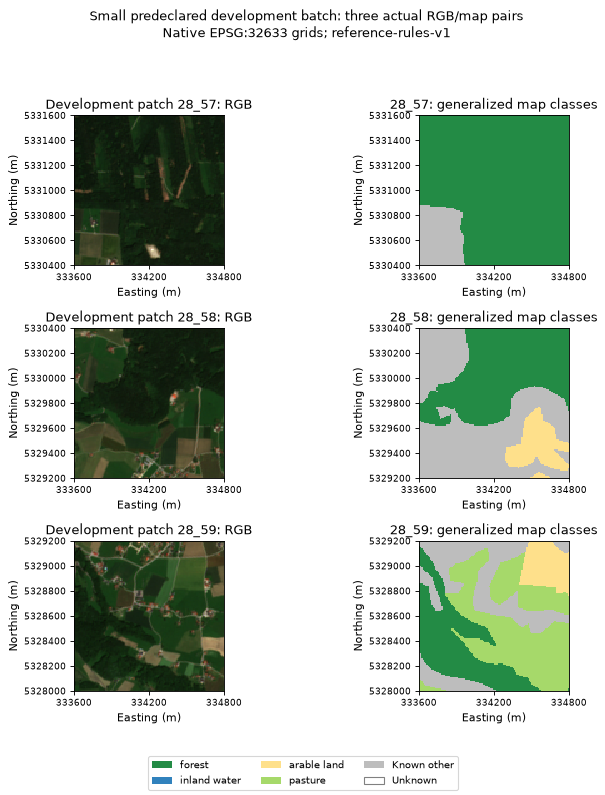

,patch,forest_fraction,inland_water_fraction,arable_land_fraction,pasture_fraction
0,28_57,0.8869,0.0,0.0000,0.0000
1,28_58,0.4206,0.0,0.1006,0.0000
2,28_59,0.2499,0.0,0.0885,0.3975


In [13]:
new_ids = [v2_ids[index] for index in NEW_EXAMPLE_POSITIONS]
fig_v2, axes_v2 = plt.subplots(3, 2, figsize=(9, 10), dpi=80)
new_evidence = []
for row, pid in enumerate(new_ids):
    summary = v2_summaries[pid]
    files = patch_files(pid, RAW / "BigEarthNet-S2", RAW / "Reference_Maps")
    left, bottom, right, top = inspect_patch(files)["rasters"]["B04"]["bounds"]
    extent = (left, right, bottom, top)
    axes_v2[row, 0].imshow(load_rgb(files, upper=DISPLAY_UPPER_DN), extent=extent,
                           interpolation="nearest")
    aggregated_map = np.full(summary["unknown_mask"].shape, 4)
    for index, name in enumerate(class_names):
        aggregated_map[summary["class_masks"][name]] = index
    aggregated_map[summary["unknown_mask"]] = 5
    axes_v2[row, 1].imshow(aggregated_map, extent=extent, cmap=cmap, norm=norm,
                           interpolation="nearest")
    suffix = "_".join(pid.split("_")[-2:])
    axes_v2[row, 0].set_title(f"Development patch {suffix}: RGB")
    axes_v2[row, 1].set_title(f"{suffix}: generalized map classes")
    for ax in axes_v2[row]:
        ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
        ax.ticklabel_format(style="plain", useOffset=False)
        ax.set_xticks(np.linspace(left, right, 3)); ax.tick_params(labelsize=8)
    new_evidence.append({"patch": suffix, **{
        name + "_fraction": summary["classes"][name]["fraction_lower"]
        for name in class_names}})
fig_v2.legend(handles=[Patch(facecolor=COLORS[name], label=name.replace("_", " "))
                      for name in class_names] +
              [Patch(facecolor="#bdbdbd", label="Known other"),
               Patch(facecolor="#ffffff", edgecolor="gray", label="Unknown")],
              loc="lower center", ncol=3, fontsize=9)
fig_v2.suptitle("Small predeclared development batch: three actual RGB/map pairs\n"
               "Native EPSG:32633 grids; reference-rules-v1", fontsize=12)
fig_v2.tight_layout(rect=(0, .07, 1, .94))
v2_output = ROOT / "outputs/development-validation-v2"
v2_output.mkdir(parents=True, exist_ok=True)
fig_v2.savefig(v2_output / "development-examples.png", dpi=110)
plt.show()
display(pd.DataFrame(new_evidence).round(4))

Visual inspection shows broadly corresponding woodland and field patterns. Patch
28_57 has small bright clearings/linear structures in RGB that the generalized
map does not resolve separately. Patch 28_58 mixes fields and woodland; gray is
known other CLC cover, not missing evidence. Patch 28_59 illustrates generalized
field boundaries and mapped pasture/arable distinctions that RGB color alone
cannot independently verify. These observations support coarse alignment and
expose reference limitations; they do not validate exact cover percentages,
contact lengths or all thematic labels.

### 11.3 Did new development evidence establish a test collection?

Recompute spatial components using actual native extents and the unchanged
2-km envelope rule. All explored images anchor their components in development.
Coverage uses full three-state references, not captions or model results;
relation controls require both true presences and retain unknown relation states.
We apply the existing gates rather than lowering them to obtain a passing status.

In [14]:
v2_footprints = verified_footprints(v2_ids, RAW)
v2_split = spatial_split(v2_footprints, v2_ids, DESIGN["spatial"])
v2_intent, v2_family, v2_relation, v2_controls = coverage_tables(
    v2_decisions, queries, v2_split.group_id)
display(v2_intent[["true", "false", "unknown", "judged_fraction",
                   "spatial_groups", "positive_outside_largest_group"]])
display(v2_family)
display(v2_relation[["both_present", "true", "false", "unknown", "missing_class"]])
display(pd.Series({"loaded_development": len(v2_ids),
                   "components": v2_split.group_id.nunique(),
                   "countries": source_checks.country.nunique(),
                   "test_images": int(v2_split.split.eq("test").sum())}))
assert v2_split.split.eq("development").all()
assert v2_controls == current["relation_controls"]["development"]
display(pd.DataFrame({"unchanged_development_gate_failure": current["development_gate_failures"]}))

,true,false,unknown,judged_fraction,spatial_groups,positive_outside_largest_group
intent_id,,,,,,
single-forest,13,0,0,1.0,1,0
single-inland-water,6,7,0,1.0,1,0
single-arable-land,5,8,0,1.0,1,0
single-pasture,6,7,0,1.0,1,0
both-forest-water,6,7,0,1.0,1,0
adjacent-forest-water,6,7,0,1.0,1,0
both-arable-pasture,3,10,0,1.0,1,0
adjacent-arable-pasture,3,10,0,1.0,1,0


,true,false,unknown,patch_intent_count,judged_fraction,unique_images
family_id,,,,,,
forest-water,31,21,0,52,1.0,13
arable-pasture,17,35,0,52,1.0,13


,both_present,true,false,unknown,missing_class
intent_id,,,,,
adjacent-forest-water,6,6,0,0,7
adjacent-arable-pasture,3,3,0,0,10


loaded_development    13
components             1
countries              1
test_images            0
dtype: int64

,unchanged_development_gate_failure
0,single-forest: candidate count 13 < 20
1,single-forest: negatives 0 < 10
2,single-forest: positive dispersion 0 < 10
3,single-forest: spatial groups 1 < 3
4,single-inland-water: candidate count 13 < 20
5,single-inland-water: positives 6 < 10
6,single-inland-water: negatives 7 < 10
7,single-inland-water: positive dispersion 0 < 10
8,single-inland-water: spatial groups 1 < 3
9,single-arable-land: candidate count 13 < 20


The enlarged development collection still has one component and no forest
negative. Forest/water controls remain six true / zero false; arable/pasture now
has three true / zero false. The three real additions increase technical evidence,
but do not fix geography or hard-relation coverage. No planned image is acquired
or assigned to test; all 250 planned IDs remain unassigned. No test reference,
embedding or ranking has been generated.

### 11.4 Freeze decision and smallest next action

`benchmark-candidate-v2` explicitly records this revision and remains
**blocked-not-frozen**. Both original and revised candidates are integrity checked;
the default loader refuses both for final evaluation. A controlled positive
protocol fixture tests successful validation when all structural/coverage
requirements genuinely match; it is not a fabricated research dataset.

The official complete S2/map archives total 63,534,101,678 bytes. This task does
not authorize downloading them. The smallest next action is to provide an
indexed official endpoint or a provenance-verified local subset for the **first
25 planned IDs**, each with B04/B03/B02 and its original reference TIFF (100 files).
Their byte sizes and checksums must be checked before further batches. No new
alternative dataset or relaxed freeze criteria are proposed as a workaround.
Broader development geometry, thematic plausibility and held-out coverage must
still pass before a real freeze. Work package 5 remains gated.

In [15]:
for version in [CANDIDATE_PATH, CURRENT_CANDIDATE]:
    try:
        load_benchmark_record(version, ROOT)
    except ValueError as error:
        print(version.name, "rejected as expected:", error)
    else:
        raise AssertionError("Incomplete candidate unexpectedly accepted")
(v2_output / "figure-provenance.json").write_text(json.dumps({
    "candidate_version": current["version"], "candidate_sha256": file_digest(CURRENT_CANDIDATE),
    "selected_development_ids": new_ids,
    "figure_sha256": file_digest(v2_output / "development-examples.png")
}, indent=2) + "\n")
print("Saved current development diagnostics and figure; no freeze or final evaluation.")

benchmark-candidate-v1.json rejected as expected: Benchmark is blocked, not frozen; final evaluation is prohibited
benchmark-candidate-v2.json rejected as expected: Benchmark is blocked, not frozen; final evaluation is prohibited
Saved current development diagnostics and figure; no freeze or final evaluation.


## 12. Do the completed archives yield the exact native 25-patch batch?

Both official BigEarthNet-v2.0.0 archives are now complete and their published
MD5 checks passed: 63,251,710,377 S2 bytes and 282,391,301 map bytes. The fixed
first 25 acquisition IDs are unchanged. Extraction reused trusted completed
checks whose identities/file times still match, avoiding redundant 63-GB hash
passes. It sequentially scanned both tar streams for exact-name uniqueness.
Only 75 new RGB TIFFs were written; all 25 valid maps were reused. No download,
full uncompressed dataset, model execution or additional image batch is needed.

Run `scripts/validate_archive_access.py` before this notebook to reproduce the
local source/split/coverage artifacts. They describe the completed native data
stage, separately from the unchanged blocked benchmark candidate.
Historical source displays include provisional Test-side images; they did not
change rules or queries. Section 14 uses Development only for the new visual
reference-suitability inspection.


In [16]:
from earth_observation.archive_validation import (
    inspect_reference_selection,
    validate_raster_selection,
)

archive_access = json.loads(ARCHIVE_ACCESS_PATH.read_text())
assert (
    file_digest(ROOT / archive_access["selection_file"])
    == (archive_access["selection_sha256"])
)
archive_ids = archive_access["planned_patch_ids"]
assert archive_ids == planned.patch_id.head(25).tolist()
map_sources, map_decisions, map_summaries = inspect_reference_selection(
    archive_access["reference_extraction"], archive_ids, RAW, rules, queries
)
completion = json.loads(COMPLETION_PATH.read_text())
archive_sources = validate_raster_selection(
    archive_access["complete_extractions"],
    archive_ids,
    RAW,
    catalog,
    archive_access.get("text_annotations", []),
)
complete_pairs = sum(
    inspect_patch(patch_files(pid, RAW / "BigEarthNet-S2", RAW / "Reference_Maps"))[
        "status"
    ]
    == "aligned"
    for pid in archive_ids
)
display(
    pd.Series(
        {
            "planned_patches": 25,
            "expected_RGB_TIFFs": 75,
            "reference_maps_loaded_and_checksum_verified": len(map_sources),
            "reference_payload_bytes": 25154,
            "complete_RGB_map_pairs_present": complete_pairs,
            "new_technically_validated_patches": len(archive_sources),
            "text_verified_patches": int(
                archive_sources.text_status.eq("verified").sum()
            ),
        }
    )
)
display(
    map_sources[
        ["crs", "height", "width", "dtype", "nodata", "masked_pixels"]
    ].drop_duplicates()
)

planned_patches                                   25
expected_RGB_TIFFs                                75
reference_maps_loaded_and_checksum_verified       25
reference_payload_bytes                        25154
complete_RGB_map_pairs_present                    25
new_technically_validated_patches                 25
text_verified_patches                              0
dtype: int64

,crs,height,width,dtype,nodata,masked_pixels
patch_id,,,,,,
S2B_MSIL2A_20170801T095029_N9999_R079_T33TXN_01_53,EPSG:32633,120,120,uint16,0.0,0


### 12.1 Which semantic gaps does this fixed batch address?

The existing 5% class-presence and 60-m contact rules remain unchanged. These
counts describe all 25 new native RGB/map pairs; section 13 separates their
spatially assigned collections. Map-derived states remain agreement with a
generalized land-cover reference, not independently verified visual truth.
A native 10-m TIFF grid does not improve the CLC2018 mapping accuracy described
in section 11.2. Missing text annotation evidence remains separately unknown.

In [17]:
map_coverage = map_decisions.apply(
    lambda states: states.value_counts().reindex(
        ["true", "false", "unknown"], fill_value=0
    )
).T
map_controls = []
for intent in queries["intents"]:
    if intent["kind"] != "adjacency":
        continue
    both_present = [
        pid
        for pid in archive_ids
        if all(
            map_summaries[pid]["classes"][name]["state"] == "true"
            for name in intent["classes"]
        )
    ]
    relation_counts = (
        map_decisions.loc[both_present, intent["intent_id"]]
        .value_counts()
        .reindex(["true", "false", "unknown"], fill_value=0)
    )
    map_controls.append(
        {
            "intent_id": intent["intent_id"],
            "both_present": len(both_present),
            **relation_counts.to_dict(),
        }
    )
display(map_coverage)
display(pd.DataFrame(map_controls).set_index("intent_id"))

,true,false,unknown
single-forest,16,9,0
single-inland-water,1,24,0
single-arable-land,17,8,0
single-pasture,2,23,0
both-forest-water,0,25,0
adjacent-forest-water,0,25,0
both-arable-pasture,1,24,0
adjacent-arable-pasture,1,24,0


,both_present,true,false,unknown
intent_id,,,,
adjacent-forest-water,0,0,0,0
adjacent-arable-pasture,1,1,0,0


The new batch adds nine forest negatives, but no forest/water both-present
example. Arable/pasture has one true relation and zero false relations when
both classes are present. Hence the batch does not resolve hard-relation
coverage. No rule, query, threshold or selection criterion is adjusted.
Text annotation status is tracked separately from judged map reference states.

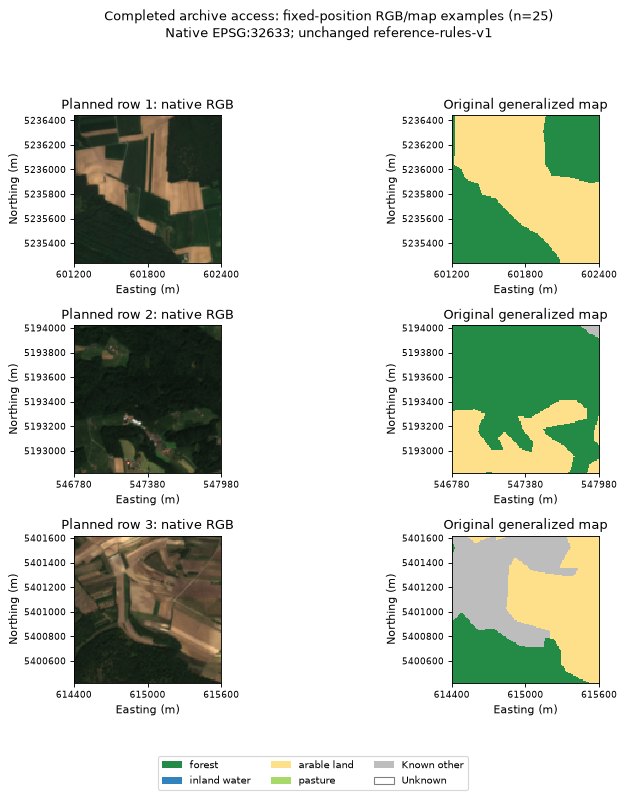

In [18]:
fig_archive, archive_axes = plt.subplots(3, 2, figsize=(10, 10), dpi=80)
for row, position in enumerate(ARCHIVE_EXAMPLE_POSITIONS):
    pid = archive_ids[position]
    summary = map_summaries[pid]
    files = patch_files(pid, RAW / "BigEarthNet-S2", RAW / "Reference_Maps")
    left, bottom, right, top = archive_sources.loc[pid, "bounds"]
    extent = (left, right, bottom, top)
    archive_axes[row, 0].imshow(
        load_rgb(files, upper=DISPLAY_UPPER_DN),
        extent=extent,
        interpolation="nearest",
    )
    display_map = np.full(summary["unknown_mask"].shape, 4)
    for index, name in enumerate(class_names):
        display_map[summary["class_masks"][name]] = index
    display_map[summary["unknown_mask"]] = 5
    archive_axes[row, 1].imshow(
        display_map,
        extent=extent,
        cmap=cmap,
        norm=norm,
        interpolation="nearest",
    )
    archive_axes[row, 0].set_title(f"Planned row {position + 1}: native RGB")
    archive_axes[row, 1].set_title("Original generalized map")
    for axis in archive_axes[row]:
        axis.set_xlabel("Easting (m)")
        axis.set_ylabel("Northing (m)")
        axis.ticklabel_format(style="plain", useOffset=False)
        axis.set_xticks(np.linspace(left, right, 3))
        axis.tick_params(labelsize=8)
fig_archive.legend(
    handles=[
        Patch(facecolor=COLORS[name], label=name.replace("_", " "))
        for name in class_names
    ]
    + [
        Patch(facecolor="#bdbdbd", label="Known other"),
        Patch(facecolor="#ffffff", edgecolor="gray", label="Unknown"),
    ],
    loc="lower center",
    ncol=3,
    fontsize=9,
)
fig_archive.suptitle(
    "Completed archive access: fixed-position RGB/map examples (n=25)\n"
    "Native EPSG:32633; unchanged reference-rules-v1"
)
fig_archive.tight_layout(rect=(0, 0.08, 1, 0.94))
archive_output = ROOT / "outputs/archive-data-access-v1"
archive_output.mkdir(parents=True, exist_ok=True)
fig_archive.savefig(archive_output / "rgb-map-examples.png", dpi=110)
map_coverage.to_csv(archive_output / "reference-only-coverage.csv")
plt.show()

### 12.2 How should the visual comparisons be interpreted?

Examples are the first three fixed acquisition positions, selected without
rankings or relevance filters. RGB display is `clip(DN / 3000, 0, 1)` in
B04/B03/B02 order; source NoData/masked pixels become NaN, not black negative
observations. No resampling is performed. In row 1 the map merges field strips visible in RGB;
row 2 has small bright clearings/structures within a broad mapped forest region.
Row 3 includes gray CLC code 243 (agriculture with significant natural vegetation),
a known other class rather than missing evidence. Broad woodland/field placement
is plausible, while fine structures and boundaries remain unresolved. Visual
inspection does not overwrite reference states.

The 25 pairs pass exact member-byte, catalog-ID, native band/grid/extent/dtype,
NoData and finite-value checks. Original text annotation pairing is reported
separately; missing records are unknown, not fabricated from catalog labels.

## 13. Does native spatial separation provide adequate held-out coverage?

Apply the existing EPSG:3035 envelope protocol with inclusive 2-km distance and
all acquisition dates. Previous Development components remain anchored; other
components use the unchanged seeded hash split. Visual checks assess source
alignment only; no rules or queries were tuned using these images.

The 25 new IDs are disjoint from the 13 existing IDs. Native duplicate footprints,
projected-envelope overlaps with previous Development, and connections to
anchored components are explicitly checked. Spatial assignments do not establish
a frozen benchmark and do not authorize test embeddings or model rankings.

distinct_technically_validated_patches    38
duplicate_patch_IDs                        0
spatial_groups                            25
new_connections_to_development             0
development                               22
test                                      16
dtype: int64

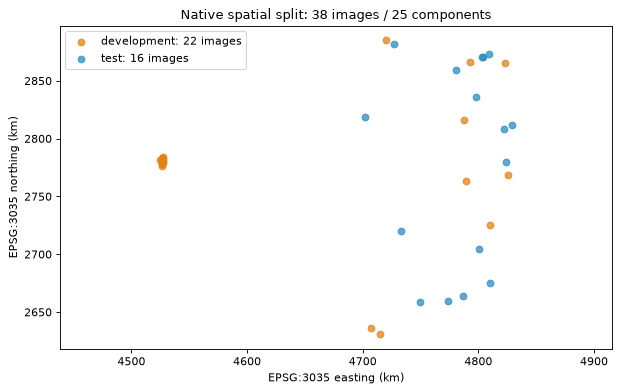

In [19]:
spatial = pd.read_csv(archive_output / "spatial-assignments.csv", index_col="patch_id")
footprints = pd.read_csv(
    archive_output / "spatial-footprints.csv", index_col="patch_id"
)
display(
    pd.Series(
        {
            "distinct_technically_validated_patches": completion[
                "distinct_validated_patches"
            ],
            "duplicate_patch_IDs": completion["duplicate_patch_ids"],
            "spatial_groups": completion["spatial_groups"],
            "new_connections_to_development": completion[
                "new_images_in_anchored_development_groups"
            ],
            **completion["split_counts"],
        }
    )
)
fig_spatial, axis_spatial = plt.subplots(figsize=(8, 5), dpi=80)
for split, color in [("development", "#e08214"), ("test", "#2b8cbe")]:
    subset = footprints.loc[spatial.index[spatial.split.eq(split)]]
    axis_spatial.scatter(
        (subset.left + subset.right) / 2000,
        (subset.bottom + subset.top) / 2000,
        color=color,
        label=f"{split}: {len(subset)} images",
        alpha=0.75,
    )
axis_spatial.set_title("Native spatial split: 38 images / 25 components")
axis_spatial.set_xlabel("EPSG:3035 easting (km)")
axis_spatial.set_ylabel("EPSG:3035 northing (km)")
axis_spatial.legend()
axis_spatial.set_aspect("equal", adjustable="datalim")
fig_spatial.tight_layout()
fig_spatial.savefig(archive_output / "spatial-groups.png", dpi=110)
plt.show()

In [20]:
for split in ["all", "development", "test"]:
    print(f"Reference coverage: {split}")
    intent_coverage = pd.DataFrame(completion["coverage"][split]["intent"]).set_index(
        "intent_id"
    )
    display(
        intent_coverage[
            [
                "true",
                "false",
                "unknown",
                "spatial_groups",
                "positive_outside_largest_group",
            ]
        ]
    )
    display(
        pd.DataFrame(completion["coverage"][split]["family"]).set_index("family_id")
    )
    relation_coverage = pd.DataFrame(
        completion["coverage"][split]["relations"]
    ).set_index("intent_id")
    display(relation_coverage[["both_present", "true", "false", "unknown"]])
print("Current freeze blockers:")
for blocker in completion["freeze_blockers"]:
    print("-", blocker)
assert load_benchmark_record(CURRENT_CANDIDATE, ROOT, False)["status"] == (
    "blocked-not-frozen"
)

Reference coverage: all


,true,false,unknown,spatial_groups,positive_outside_largest_group
intent_id,,,,,
single-forest,29,9,0,25,16
single-inland-water,7,31,0,25,1
single-arable-land,22,16,0,25,17
single-pasture,8,30,0,25,2
both-forest-water,6,32,0,25,0
adjacent-forest-water,6,32,0,25,0
both-arable-pasture,4,34,0,25,1
adjacent-arable-pasture,4,34,0,25,1


,true,false,unknown,patch_intent_count,judged_fraction,unique_images
family_id,,,,,,
forest-water,48,104,0,152,1.0,38
arable-pasture,38,114,0,152,1.0,38


,both_present,true,false,unknown
intent_id,,,,
adjacent-forest-water,6,6,0,0
adjacent-arable-pasture,4,4,0,0


Reference coverage: development


...

Reference coverage: test


,true,false,unknown,spatial_groups,positive_outside_largest_group
intent_id,,,,,
single-forest,11,5,0,15,9
single-inland-water,0,16,0,15,0
single-arable-land,12,4,0,15,10
single-pasture,1,15,0,15,0
both-forest-water,0,16,0,15,0
adjacent-forest-water,0,16,0,15,0
both-arable-pasture,1,15,0,15,0
adjacent-arable-pasture,1,15,0,15,0


,true,false,unknown,patch_intent_count,judged_fraction,unique_images
family_id,,,,,,
forest-water,11,53,0,64,1.0,16
arable-pasture,15,49,0,64,1.0,16


,both_present,true,false,unknown
intent_id,,,,
adjacent-forest-water,0,0,0,0
adjacent-arable-pasture,1,1,0,0


Current freeze blockers:
- 225 selected patches lack verified RGB/map access
- single-forest: candidate count 16 < 20
- single-forest: negatives 5 < 10
- single-forest: positive dispersion 9 < 10
- single-inland-water: candidate count 16 < 20
- single-inland-water: positives 0 < 10
- single-inland-water: positive dispersion 0 < 10
- single-arable-land: candidate count 16 < 20
- single-arable-land: negatives 4 < 10
- single-pasture: candidate count 16 < 20
- single-pasture: positives 1 < 10
- single-pasture: positive dispersion 0 < 10
- both-forest-water: candidate count 16 < 20
- both-forest-water: positives 0 < 10
- both-forest-water: positive dispersion 0 < 10
- adjacent-forest-water: candidate count 16 < 20
- adjacent-forest-water: positives 0 < 10
- adjacent-forest-water: positive dispersion 0 < 10
- both-arable-pasture: candidate count 16 < 20
- both-arable-pasture: positives 1 < 10
- both-arable-pasture: positive dispersion 0 < 10
- adjacent-arable-pasture: candidate count 16 < 2

There are 38 unique native pairs in 25 components, with 22 images on the
Development side and 16 on the Test side. The new batch contributes nine and 16
images respectively; no new component connects to the original Development
component. The 16 test-side images occupy 15 components, but have zero inland-water
positives, one pasture positive and insufficient counts for multiple intents.
Both-present controls have zero forest/water examples and one true arable/pasture
example on the Test side; neither family has a false relation. All-collection
controls remain six true forest/water and four true arable/pasture, zero false.

Family totals count patch × intent states (38 × 4 = 152 per family), not
independent samples. The main collection uses all spatially assigned images;
relation controls are separately filtered both-present experiments.

The access stage now has exactly 100 TIFFs, with all 25 new pairs technically
validated. Missing original text annotation evidence is reported separately.
The remaining 225 planned IDs were not acquired or substituted.
`benchmark-candidate-v2` remains **blocked-not-frozen** and its default loader
still refuses final evaluation. Adequate test/control coverage, reference-scale
suitability and source completeness remain prerequisites; no criteria are relaxed
and no statistics or model runs are performed.

## 14. Does the complete planned inventory make a freeze feasible?

This assessment preserves all 250 IDs and the earlier access artifacts. One
sequential scan per local archive extracted exactly 1,000 selected TIFFs:
900 new files and 100 valid reused files, 22,150,304 native bytes. No new archive
transfer or complete unpacking occurred. The 13 earlier Development patches
remain separate, bringing the collection to 263 unique RGB/map pairs.

Text access uses pinned official Parquet footer/patch-ID column ranges to locate
exact zero-based row positions, then `rows?offset=…&length=1` for original
annotations. Filter/search server failures did not justify a full 467-MB download.
The cumulative text ledger remains below 50 MB and retains failed allocations.
The converted Parquet commit pins the index source; the rows API cannot accept a
revision, so exact response digests identify the independent annotation snapshot.
Answers are source examples only and never determine relevance or rankings.


In [21]:
full_access = json.loads(FULL_ACCESS_PATH.read_text())
full_completion = json.loads((FULL_OUTPUT / "completion.json").read_text())
full_record = load_benchmark_record(FULL_CANDIDATE, ROOT, require_frozen=False)
full_ids = full_access["planned_patch_ids"]
assert full_ids == planned.patch_id.tolist()
full_sources = validate_raster_selection(
    full_access["complete_extractions"],
    full_ids,
    RAW,
    catalog,
    full_access["text_annotations"],
)
full_map_receipt = next(
    r
    for r in full_access["complete_extractions"]
    if r["archive"]["name"] == "Reference_Maps.tar.zst"
)
_, full_decisions, full_summaries = inspect_reference_selection(
    full_map_receipt,
    full_ids,
    RAW,
    rules,
    queries,
)
pd.DataFrame(
    [
        {
            "inventory": "Planned selection",
            "planned": 250,
            "technical": len(full_sources),
            "original_text": int(full_sources.text_status.eq("verified").sum()),
            "fully_available": int(full_sources.text_status.eq("verified").sum()),
        },
        {
            "inventory": "Earlier Development",
            "planned": 13,
            "technical": 13,
            "original_text": 13,
            "fully_available": 13,
        },
    ]
).set_index("inventory")


,planned,technical,original_text,fully_available
inventory,,,,
Planned selection,250,250,241,241
Earlier Development,13,13,13,13


### 14.1 Which original texts actually match?

Select one original row at the first indexed position for each existing patch.
Nine planned IDs are absent from the pinned text Parquet: all relevant ID-column
chunks were inspected, using complete min/max metadata to exclude other groups.
Their raster pairs remain valid; their original text is explicitly unknown.
They are neither substituted nor removed from the unfiltered main collection.
The first 25 planned patches have 24 exact text matches and one absent entry.

The following examples are the first Development selection in each of three
predeclared countries. Matching checks additionally require exact S1 identity,
country, and native raster-center agreement in WGS84 within 1e-8 degree.


In [22]:
full_assignments = pd.DataFrame(full_record["spatial_inventory"]).set_index("patch_id")
dev_example_ids = [
    next(
        pid
        for pid in full_ids
        if full_sources.loc[pid, "country"] == country
        and full_assignments.loc[pid, "split"] == "development"
    )
    for country in DEV_EXAMPLE_COUNTRIES
]
original_texts = pd.DataFrame(full_access["text_annotations"]).set_index("patch_id")
display(
    original_texts.reindex(dev_example_ids)[
        ["ID", "row_idx", "input", "output", "country"]
    ]
)
display(
    pd.DataFrame(
        {
            "patch_id": full_access["text_evidence"]["missing_patch_ids"],
            "original_text_status": "unknown: absent from pinned source",
        }
    )
)


,ID,row_idx,input,output,country
patch_id,,,,,
S2B_MSIL2A_20171219T095409_N9999_R079_T33TXN_25_01,6688865,6688864,Does any inland water and marine waters share ...,no,Austria
S2B_MSIL2A_20171107T105229_N9999_R051_T31UER_71_18,6368607,6368606,Would you identify any arable land as lying ad...,yes,Belgium
S2B_MSIL2A_20180515T094029_N9999_R036_T35VNJ_13_37,8375024,8375023,Does any coniferous forest directly border lan...,yes,Finland


,patch_id,original_text_status
0,S2B_MSIL2A_20171219T095409_N9999_R079_T33TWN_7...,unknown: absent from pinned source
1,S2B_MSIL2A_20171107T105229_N9999_R051_T31UER_9...,unknown: absent from pinned source
2,S2B_MSIL2A_20180506T105029_N9999_R051_T31UER_3...,unknown: absent from pinned source
3,S2B_MSIL2A_20180506T105029_N9999_R051_T31UER_5...,unknown: absent from pinned source
4,S2A_MSIL2A_20170717T113321_N9999_R080_T29UPA_3...,unknown: absent from pinned source
5,S2A_MSIL2A_20170720T100031_N9999_R122_T34UDG_8...,unknown: absent from pinned source
6,S2B_MSIL2A_20171015T104009_N9999_R008_T31UGR_2...,unknown: absent from pinned source
7,S2A_MSIL2A_20170818T103021_N9999_R108_T32TMT_4...,unknown: absent from pinned source
8,S2A_MSIL2A_20170818T103021_N9999_R108_T32TMT_2...,unknown: absent from pinned source


### 14.2 Are the generalized references visually adequate?

Use only the predeclared Development examples above, without class or ranking
selection. RGB display clips DN at 3,000, as before; maps and RGB retain native
10-m grids without resampling. These examples can reveal coarse agreement and
limitations, but cannot verify fine boundary truth or establish a validated
60-m visual adjacency threshold. No Test image is visually inspected here.


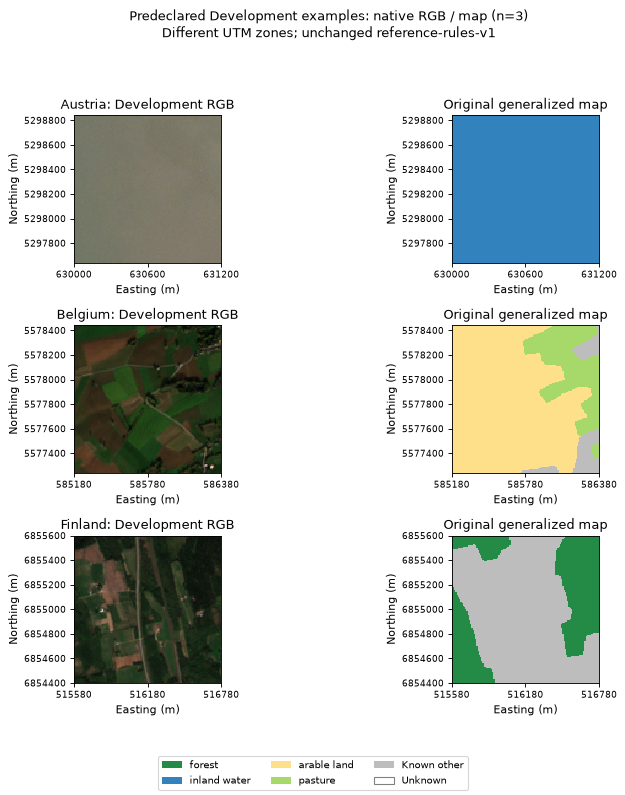

In [23]:
fig_full, full_axes = plt.subplots(3, 2, figsize=(10, 10), dpi=80)
for row, pid in enumerate(dev_example_ids):
    summary = full_summaries[pid]
    files = patch_files(pid, RAW / "BigEarthNet-S2", RAW / "Reference_Maps")
    left, bottom, right, top = full_sources.loc[pid, "bounds"]
    extent = (left, right, bottom, top)
    full_axes[row, 0].imshow(
        load_rgb(files, upper=DISPLAY_UPPER_DN),
        extent=extent,
        interpolation="nearest",
    )
    display_map = np.full(summary["unknown_mask"].shape, 4)
    for index, name in enumerate(class_names):
        display_map[summary["class_masks"][name]] = index
    display_map[summary["unknown_mask"]] = 5
    full_axes[row, 1].imshow(
        display_map,
        extent=extent,
        cmap=cmap,
        norm=norm,
        interpolation="nearest",
    )
    full_axes[row, 0].set_title(full_sources.loc[pid, "country"] + ": Development RGB")
    full_axes[row, 1].set_title("Original generalized map")
    for axis in full_axes[row]:
        axis.set_xlabel("Easting (m)")
        axis.set_ylabel("Northing (m)")
        axis.ticklabel_format(style="plain", useOffset=False)
        axis.set_xticks(np.linspace(left, right, 3))
        axis.tick_params(labelsize=8)
fig_full.legend(
    handles=[
        Patch(facecolor=COLORS[name], label=name.replace("_", " "))
        for name in class_names
    ]
    + [
        Patch(facecolor="#bdbdbd", label="Known other"),
        Patch(facecolor="#ffffff", edgecolor="gray", label="Unknown"),
    ],
    loc="lower center",
    ncol=3,
    fontsize=9,
)
fig_full.suptitle(
    "Predeclared Development examples: native RGB / map (n=3)\n"
    "Different UTM zones; unchanged reference-rules-v1"
)
fig_full.tight_layout(rect=(0, 0.08, 1, 0.94))
fig_full.savefig(FULL_OUTPUT / "development-rgb-map.png", dpi=110)
plt.show()


**Observed Development examples:** the Austrian RGB is almost textureless and
its map is entirely inland water (CLC 512), so it provides no boundary comparison.
Belgium shows individual field strips and a settlement; the map merges much of
that structure into arable/pasture regions and known other cover. Finland shows
field strips mixed with dark vegetation; the large gray region includes CLC 243
(agriculture with natural vegetation) and 324, both known other cover. Gray is
not missing data. Broad visual plausibility does not independently verify class
identity or the exact shared boundaries. No visual conclusion comes from Test.

### 14.3 What coverage does the unchanged spatial protocol provide?

All 22 previously Development-assigned IDs anchor their complete components.
Every acquisition date participates in the inclusive 2-km envelope-distance graph;
nonanchored components keep the original seeded hash assignment. A larger inventory
may join components, so test-side membership is provisional until a valid freeze.
Main retrieval contains every assigned image; the both-present relation controls
are separate filtered experiments. Family counts are patch × intent states,
not independent images. Unknown original text is separate from unknown map truth.


,development,test
Austria,22,16
Belgium,12,13
Finland,10,15
Ireland,14,11
Kosovo,10,15
Lithuania,17,8
Luxembourg,14,11
Portugal,14,11
Serbia,6,19
Switzerland,9,16


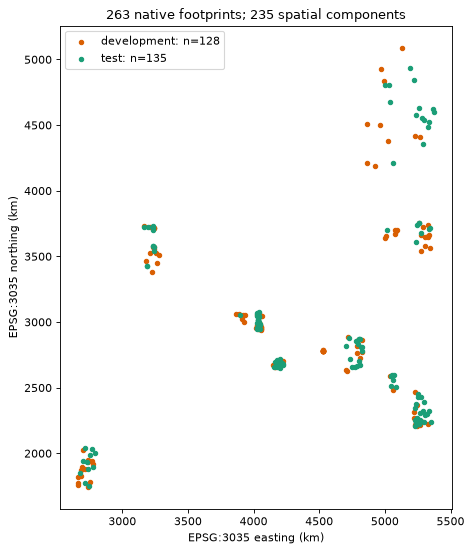

Main map agreement — all


,intent_id,family_id,true,false,unknown,judged_fraction,spatial_groups,positive_groups,negative_groups,positive_outside_largest_group,negative_outside_largest_group
0,single-forest,forest-water,164,99,0,1.0,235,143,94,151,96
1,single-inland-water,forest-water,16,247,0,1.0,235,11,225,10,240
2,single-arable-land,arable-pasture,106,157,0,1.0,235,96,140,101,149
3,single-pasture,arable-pasture,76,187,0,1.0,235,66,172,70,180
4,both-forest-water,forest-water,11,252,0,1.0,235,6,230,5,245
5,adjacent-forest-water,forest-water,9,254,0,1.0,235,4,232,3,247
6,both-arable-pasture,arable-pasture,28,235,0,1.0,235,24,213,25,225
7,adjacent-arable-pasture,arable-pasture,26,237,0,1.0,235,22,215,23,227


Separate both-present relation control — all


,intent_id,family_id,both_present,missing_class,unknown_presence,true,false,unknown,judged_fraction,spatial_groups,true_outside_largest_group,false_outside_largest_group
0,adjacent-forest-water,forest-water,11,252,0,9,2,0,1.0,6,3,1
1,adjacent-arable-pasture,arable-pasture,28,235,0,26,2,0,1.0,24,23,1


Main map agreement — test


,intent_id,family_id,true,false,unknown,judged_fraction,spatial_groups,positive_groups,negative_groups,positive_outside_largest_group,negative_outside_largest_group
0,single-forest,forest-water,89,46,0,1.0,125,83,44,87,44
1,single-inland-water,forest-water,6,129,0,1.0,125,6,119,5,127
2,single-arable-land,arable-pasture,50,85,0,1.0,125,46,79,48,83
3,single-pasture,arable-pasture,40,95,0,1.0,125,37,90,38,93
4,both-forest-water,forest-water,3,132,0,1.0,125,3,122,2,130
5,adjacent-forest-water,forest-water,2,133,0,1.0,125,2,123,1,131
6,both-arable-pasture,arable-pasture,10,125,0,1.0,125,9,117,8,123
7,adjacent-arable-pasture,arable-pasture,9,126,0,1.0,125,8,118,7,124


Separate both-present relation control — test


,intent_id,family_id,both_present,missing_class,unknown_presence,true,false,unknown,judged_fraction,spatial_groups,true_outside_largest_group,false_outside_largest_group
0,adjacent-forest-water,forest-water,3,132,0,2,1,0,1.0,3,1,0
1,adjacent-arable-pasture,arable-pasture,10,125,0,9,1,0,1.0,9,7,0


In [24]:
display(pd.DataFrame(full_completion["country_split_counts"]).T)
full_spatial = pd.read_csv(FULL_OUTPUT / "spatial-footprints.csv").set_index("patch_id")
fig_full_space, ax_full_space = plt.subplots(figsize=(8, 7))
for split, color in [("development", "#d95f02"), ("test", "#1b9e77")]:
    selected_ids = full_assignments.index[full_assignments.split.eq(split)]
    positions = full_spatial.loc[selected_ids]
    ax_full_space.scatter(
        (positions.left + positions.right) / 2000,
        (positions.bottom + positions.top) / 2000,
        s=15,
        color=color,
        label=f"{split}: n={len(positions)}",
    )
ax_full_space.set_xlabel("EPSG:3035 easting (km)")
ax_full_space.set_ylabel("EPSG:3035 northing (km)")
ax_full_space.set_title("263 native footprints; 235 spatial components")
ax_full_space.set_aspect("equal")
ax_full_space.legend()
fig_full_space.tight_layout()
fig_full_space.savefig(FULL_OUTPUT / "full-spatial.png", dpi=110)
plt.show()
for split in ["all", "test"]:
    print(f"Main map agreement — {split}")
    display(pd.DataFrame(full_completion["coverage"][split]["intent"]))
    print(f"Separate both-present relation control — {split}")
    display(pd.DataFrame(full_completion["coverage"][split]["relations"]))


### 14.4 Which freeze gates still fail?

The collection closes the native-access, broad geography and zero-Test gaps.
The Test side has 135 images in 125 groups; both-present false relations now
exist, one per family. Their mere existence does not satisfy the required ten
false controls or five outside the largest negative group. Inland-water positives
are six; forest/water conjunction positives three and adjacency positives two.
Arable/pasture adjacency has nine positives, and its conjunction has only eight
positives outside the largest positive group. All map states are judged; this
says nothing about the source map's fine boundary accuracy.

Generalized CLC2018 uses 25-ha mapping units and 100-m minimum linear width.
A 10-m raster does not refine that information. The provisional 5% threshold
(7.2 ha of a 144-ha patch) is not automatically invalid: clipped polygons may
be smaller than mapping units. However, technical alignment and three visual
examples cannot establish that 60 m of mapped contact represents visual truth.
Reference suitability therefore remains an independent failed prerequisite.


In [25]:
display(pd.DataFrame({"failed_prerequisite": full_completion["freeze_blockers"]}))
assert full_record["status"] == "blocked-not-frozen"
assert full_completion["previous_development_preserved"]
try:
    load_benchmark_record(FULL_CANDIDATE, ROOT)
except ValueError as error:
    print("Final evaluation remains prohibited:", error)


,failed_prerequisite
0,single-inland-water: positives 6 < 10
1,single-inland-water: positive dispersion 5 < 10
2,both-forest-water: positives 3 < 10
3,both-forest-water: positive dispersion 2 < 10
4,adjacent-forest-water: positives 2 < 10
5,adjacent-forest-water: positive dispersion 1 < 10
6,both-arable-pasture: positive dispersion 8 < 10
7,adjacent-arable-pasture: positives 9 < 10
8,adjacent-arable-pasture: positive dispersion 7...
9,adjacent-forest-water: relation true 2 below r...


Final evaluation remains prohibited: Benchmark is blocked, not frozen; final evaluation is prohibited


The new `benchmark-candidate-v3` records measured 263-image geometry, original
text evidence, all three-state relevance values and separate control membership.
It is justified by new data, preserves v1/v2, and remains **blocked-not-frozen**.
The complete planned inventory has 250 technical pairs, 241 exact original-text
pairs and nine source-absent text entries; including earlier Development gives
263 technical and 254 fully available pairs. No model, embedding, ranking,
statistical inference or final evaluation ran.

**Proposed decision, not implemented:** first explicitly choose between evaluating
agreement with generalized mapped boundaries and evaluating independently verified
visible relations. For map agreement, document the narrower interpretation and
validate its Development suitability; for visible relations, obtain an appropriate
independent reference. Then preregister further deterministic country/tile batches
and spatial grouping until unchanged coverage gates are met, retaining the complete
unfiltered main pool and separate controls. Do not lower gates, tune queries from
Test references, or silently omit the nine missing-text IDs. Confirm with the text
provider whether those exact IDs have original annotations before changing dataset
requirements. Existing archives need no further download; any expanded selection
needs its own explicit scope/budget decision.


## 15. Does one fixed 2,000-ID expansion support map-agreement retrieval?

**Authorized design revision: benchmark-design-v2.** Main relevance means
agreement with generalized CLC2018 categories under unchanged 5% presence and
60-m summed four-neighbor mapped contact. Adjacency is a property of the mapped
regions; it is not independently verified adjacency of visible objects. Native
10-m raster resolution does not improve the underlying 25-ha/100-m mapping
conventions. RGB/map differences remain qualitative Development diagnostics.

Missing original captions no longer block image/query retrieval when image
identity, provenance, geometry and map evidence are independently verified.
Original-caption analyses can only use actual original annotations. Missing text
is not missing map evidence and never becomes a false reference judgment.
All numerical coverage, spatial grouping and analysis policies remain unchanged.


In [26]:
from earth_observation.benchmark_expansion import (
    load_expanded_benchmark,
    verify_design_revision,
)

expanded_design = json.loads(EXPANSION_DESIGN_PATH.read_text())
verify_design_revision(expanded_design, DESIGN)
expanded_access = json.loads(EXPANSION_ACCESS_PATH.read_text())
expanded_record = load_expanded_benchmark(
    EXPANSION_CANDIDATE_PATH, ROOT, require_frozen=False
)
expanded_completion = json.loads((EXPANSION_OUTPUT / "completion.json").read_text())
expanded_plan = pd.read_csv(ROOT / expanded_access["selection_file"])
previous_plan = pd.read_csv(ROOT / "manifests/coverage-selection-v1.csv")
assert len(expanded_plan) == 2000
for country in previous_plan.country.unique():
    assert (
        previous_plan.loc[previous_plan.country.eq(country), "patch_id"].tolist()
        == expanded_plan.loc[expanded_plan.country.eq(country), "patch_id"]
        .head(25)
        .tolist()
    )
display(
    expanded_plan.groupby("country").agg(
        planned=("patch_id", "size"), tiles=("tile", "nunique")
    )
)


,planned,tiles
country,,
Austria,200,7
Belgium,200,3
Finland,200,21
Ireland,200,5
Kosovo,200,1
Lithuania,200,7
Luxembourg,200,1
Portugal,200,3
Serbia,200,6


### 15.1 What changed in sampling and source availability?

Quota increases from 25 to 200 in each country. The same SHA-256 seed and tile
round-robin naturally preserve each old country prefix, so no fallback sampling
rule is required. Global ranks shift as country blocks grow; all 250 old IDs are
retained. The fixed 2,000-ID plan was saved before new map labels were inspected.
Country quotas remain enrichment, not representative population sampling.

One sequential scan of each already local verified archive extracted 7,000 new
TIFFs and reused 1,000: 177,196,674 selected bytes, of which 155,046,370 are new
native files. Both amounts are below the 256-MiB additional budget. No archive,
text, weight or other dataset transfer occurred. This is exactly one expansion,
not repeated drawing until coverage passes.


In [27]:
expanded_sources = pd.read_csv(EXPANSION_OUTPUT / "source-checks.csv").set_index(
    "patch_id"
)
assert expanded_sources.index.tolist() == expanded_plan.patch_id.tolist()
assert expanded_sources.technical_status.eq("verified").all()
display(
    pd.DataFrame(
        [
            {
                "inventory": "Planned expansion",
                "planned": 2000,
                "technical": 2000,
                "original_text_verified": 241,
                "original_text_source_absent": 9,
                "original_text_not_requested": 1750,
            },
            {
                "inventory": "Earlier Development",
                "planned": 13,
                "technical": 13,
                "original_text_verified": 13,
                "original_text_source_absent": 0,
                "original_text_not_requested": 0,
            },
        ]
    ).set_index("inventory")
)
print("Native CRS count:", expanded_sources.crs.nunique())
print(
    "Native RGB DN range:",
    expanded_sources.rgb_valid_min_dn.min(),
    expanded_sources.rgb_valid_max_dn.max(),
)


,planned,technical,original_text_verified,original_text_source_absent,original_text_not_requested
inventory,,,,,
Planned expansion,2000,2000,241,9,1750
Earlier Development,13,13,13,0,0


Native CRS count: 7
Native RGB DN range: 1 17888


### 15.2 Does the computation agree with the map's categorical meaning?

Choose the first currently Development-assigned planned ID in each predeclared
country Austria, Belgium and Finland, without class or ranking criteria. Raw CLC
pixel counts reproduce the grouped class areas using the entire 144-ha patch as
denominator. CLC 243/324 and urban/other cover remain known other, rather than
unknown because the queries omit them. Contact counts mapped shared edges once;
diagonal contacts and boundaries outside the patch contribute no metres.

The existing hand-computed reference tests check these edge conventions and
unknown bounds. The following raw-count/fraction table and native map/RGB views
check the actual source interpretation. They establish operational map agreement,
not visual truth or equivalence to original text-generator rules.


,country,raw_clc_pixel_counts,full_patch_area_m2,mapped_fractions,mapped_contact_m
0,Austria,"{'211': 5565, '243': 5182, '311': 3653}",1440000.0,"{'forest': 0.2536805555555556, 'inland_water':...","{'arable_land|pasture': 0.0, 'forest|inland_wa..."
1,Belgium,"{'112': 878, '211': 10739, '231': 2721, '242':...",1440000.0,"{'forest': 0.0, 'inland_water': 0.0, 'arable_l...","{'arable_land|pasture': 2710.0, 'forest|inland..."
2,Finland,"{'243': 8034, '312': 1627, '313': 3115, '324':...",1440000.0,"{'forest': 0.3293055555555556, 'inland_water':...","{'arable_land|pasture': 0.0, 'forest|inland_wa..."


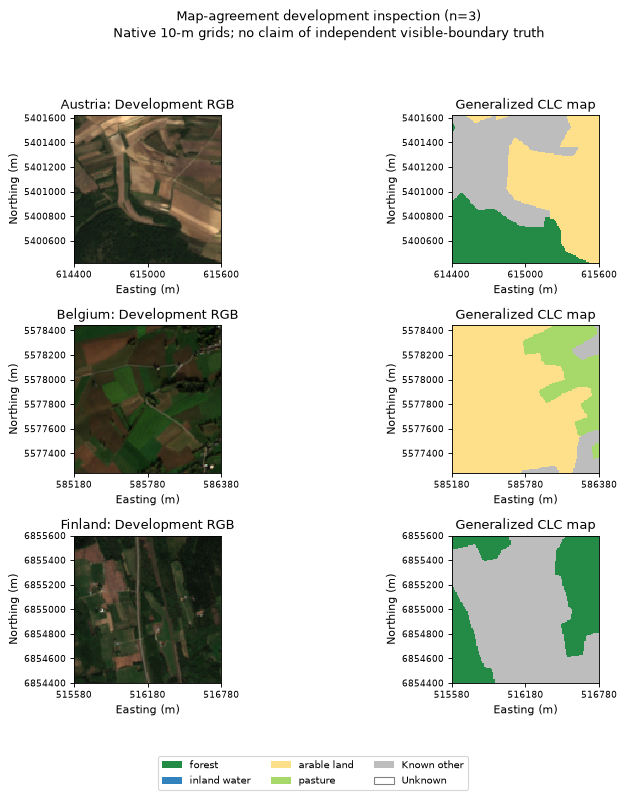

In [28]:
semantic_examples = expanded_completion["reference_validation"]["development_examples"]
display(
    pd.DataFrame(semantic_examples)[
        [
            "country",
            "raw_clc_pixel_counts",
            "full_patch_area_m2",
            "mapped_fractions",
            "mapped_contact_m",
        ]
    ]
)
expanded_example_ids = [row["patch_id"] for row in semantic_examples]
_, _, expanded_example_summaries = inspect_reference_selection(
    {
        "members": [
            member
            for receipt in json.loads(
                (CACHE / "archive-access-v3/extraction-results.json").read_text()
            )
            if receipt["archive"]["name"] == "Reference_Maps.tar.zst"
            for member in receipt["members"]
            if any("/" + pid + "/" in member["name"] for pid in expanded_example_ids)
        ]
    },
    expanded_example_ids,
    RAW,
    rules,
    queries,
)
fig_expanded, expanded_axes = plt.subplots(3, 2, figsize=(10, 10), dpi=80)
for row, pid in enumerate(expanded_example_ids):
    summary = expanded_example_summaries[pid]
    files = patch_files(pid, RAW / "BigEarthNet-S2", RAW / "Reference_Maps")
    native = inspect_patch(files)["rasters"]["B04"]
    left, bottom, right, top = native["bounds"]
    extent = (left, right, bottom, top)
    expanded_axes[row, 0].imshow(
        load_rgb(files, upper=DISPLAY_UPPER_DN),
        extent=extent,
        interpolation="nearest",
    )
    display_map = np.full(summary["unknown_mask"].shape, 4)
    for index, name in enumerate(class_names):
        display_map[summary["class_masks"][name]] = index
    display_map[summary["unknown_mask"]] = 5
    expanded_axes[row, 1].imshow(
        display_map,
        extent=extent,
        cmap=cmap,
        norm=norm,
        interpolation="nearest",
    )
    expanded_axes[row, 0].set_title(
        semantic_examples[row]["country"] + ": Development RGB"
    )
    expanded_axes[row, 1].set_title("Generalized CLC map")
    for axis in expanded_axes[row]:
        axis.set_xlabel("Easting (m)")
        axis.set_ylabel("Northing (m)")
        axis.ticklabel_format(style="plain", useOffset=False)
        axis.set_xticks(np.linspace(left, right, 3))
        axis.tick_params(labelsize=8)
fig_expanded.legend(
    handles=[
        Patch(facecolor=COLORS[name], label=name.replace("_", " "))
        for name in class_names
    ]
    + [
        Patch(facecolor="#bdbdbd", label="Known other"),
        Patch(facecolor="#ffffff", edgecolor="gray", label="Unknown"),
    ],
    loc="lower center",
    ncol=3,
    fontsize=9,
)
fig_expanded.suptitle(
    "Map-agreement development inspection (n=3)\n"
    "Native 10-m grids; no claim of independent visible-boundary truth"
)
fig_expanded.tight_layout(rect=(0, 0.08, 1, 0.94))
fig_expanded.savefig(EXPANSION_OUTPUT / "development-rgb-map.png", dpi=110)
plt.show()


**Observed Development views:** Austria shows broad woodland and agricultural
regions, while individual field strips are generalized into CLC 243 known-other
cover. Belgium's mapped arable/pasture boundary is 2,710 m (271 native shared
edges); RGB alone does not independently verify those land-use categories.
Finland's gray CLC 243/324 region includes vegetation as well as fields, and is
known other rather than missing information. The examples support the narrower
map-agreement interpretation without correcting any map or rule.

### 15.3 How did new neighbors change the spatial structure?

All 128 previously Development-assigned images remain there. The enlarged graph
has 11 groups that merge multiple earlier groups; 86 prior images change group
identity or provisional split, including 32 former Test-side images now in
Development. No prior Development image moves into Test. Assignment changes
follow new graph connectivity and the original anchored/hash rule, not labels.
Coincident native footprints at different acquisition dates are grouped together.


expanded,development,test
previous,,
development,128,0
test,32,103


,development,test
Austria,121,92
Belgium,117,83
Finland,84,116
Ireland,126,74
Kosovo,165,35
Lithuania,109,91
Luxembourg,123,77
Portugal,100,100
Serbia,95,105
Switzerland,102,98


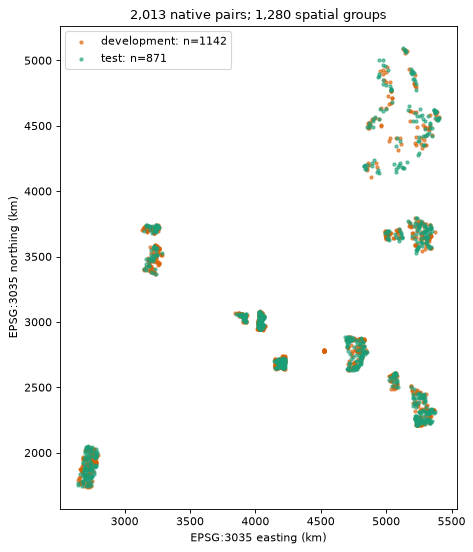

In [29]:
expanded_assignments = pd.DataFrame(expanded_record["spatial_inventory"]).set_index(
    "patch_id"
)
previous_assignments = full_assignments
transition_table = pd.crosstab(
    previous_assignments.split.rename("previous"),
    expanded_assignments.loc[previous_assignments.index, "split"].rename("expanded"),
)
display(transition_table)
display(pd.DataFrame(expanded_completion["country_split_counts"]).T)
fig_expansion_space, ax_expansion_space = plt.subplots(figsize=(8, 7))
for split, color in [("development", "#d95f02"), ("test", "#1b9e77")]:
    positions = expanded_assignments[expanded_assignments.split.eq(split)]
    ax_expansion_space.scatter(
        (positions.left + positions.right) / 2000,
        (positions.bottom + positions.top) / 2000,
        s=8,
        alpha=0.6,
        color=color,
        label=f"{split}: n={len(positions)}",
    )
ax_expansion_space.set_xlabel("EPSG:3035 easting (km)")
ax_expansion_space.set_ylabel("EPSG:3035 northing (km)")
ax_expansion_space.set_title("2,013 native pairs; 1,280 spatial groups")
ax_expansion_space.set_aspect("equal")
ax_expansion_space.legend()
fig_expansion_space.tight_layout()
fig_expansion_space.savefig(EXPANSION_OUTPUT / "spatial-structure.png", dpi=110)
plt.show()


### 15.4 Which unchanged gates pass, and which still fail?

There are 1,142 Development images and 871 Test-side images. Every intent now has
at least ten positive/negative Test references and sufficient positive spatial
spread. That closes the earlier positive-count gap. Main unknown map decisions
remain: two arable, and three water/pasture/composite decisions. Their judged
fractions are below the required 1.0. Missing captions are not these unknowns.

Separate Test controls contain 35 true / 2 false forest-water relations and
59 true / 7 false arable-pasture relations, with zero unknown relation states
inside both-present controls. Required false count is ten; deficits are eight
and three. Forest-water has only one false case outside its largest negative
group, below five. Arable-pasture false dispersion is six and passes.
No unknown is set false, no incomplete references are silently pruned, and
no further sample is drawn.


In [30]:
for split in ["all", "test"]:
    print(f"Main map agreement — {split}")
    display(pd.DataFrame(expanded_completion["coverage"][split]["intent"]))
    print(f"Separate both-present relation controls — {split}")
    display(pd.DataFrame(expanded_completion["coverage"][split]["relations"]))
display(pd.DataFrame(expanded_completion["unknown_reference_decisions"]))
display(pd.DataFrame({"failed_gate": expanded_completion["blockers"]}))
assert expanded_record["status"] == "blocked-not-frozen"
try:
    load_expanded_benchmark(EXPANSION_CANDIDATE_PATH, ROOT)
except ValueError as error:
    print("Final evaluation remains prohibited:", error)


Main map agreement — all


,intent_id,family_id,true,false,unknown,judged_fraction,spatial_groups,positive_groups,negative_groups,positive_outside_largest_group,negative_outside_largest_group
0,single-forest,forest-water,1211,801,1,0.999503,1280,776,575,1180,779
1,single-inland-water,forest-water,126,1883,4,0.998013,1280,108,1203,120,1830
2,single-arable-land,arable-pasture,801,1209,3,0.998510,1280,539,807,783,1174
3,single-pasture,arable-pasture,543,1466,4,0.998013,1280,322,1026,523,1415
4,both-forest-water,forest-water,80,1929,4,0.998013,1280,71,1226,74,1876
5,adjacent-forest-water,forest-water,74,1935,4,0.998013,1280,66,1229,68,1882
6,both-arable-pasture,arable-pasture,183,1826,4,0.998013,1280,128,1188,172,1773
7,adjacent-arable-pasture,arable-pasture,160,1849,4,0.998013,1280,113,1199,150,1796


Separate both-present relation controls — all


,intent_id,family_id,both_present,missing_class,unknown_presence,true,false,unknown,judged_fraction,spatial_groups,true_outside_largest_group,false_outside_largest_group
0,adjacent-forest-water,forest-water,80,1929,4,74,6,0,1.0,71,68,5
1,adjacent-arable-pasture,arable-pasture,183,1826,4,160,23,0,1.0,128,150,22


Main map agreement — test


...

Separate both-present relation controls — test


,intent_id,family_id,both_present,missing_class,unknown_presence,true,false,unknown,judged_fraction,spatial_groups,true_outside_largest_group,false_outside_largest_group
0,adjacent-forest-water,forest-water,37,831,3,35,2,0,1.0,35,33,1
1,adjacent-arable-pasture,arable-pasture,66,802,3,59,7,0,1.0,48,53,6


,patch_id,split,unknown_area_m2,unknown_fraction,unexpected_codes,masked_pixels
0,S2B_MSIL2A_20170924T093019_N9999_R136_T36VVQ_1...,test,103300.0,0.071736,[],0
1,S2B_MSIL2A_20170716T093039_N9999_R136_T36VVR_0...,test,236700.0,0.164375,[],0
2,S2B_MSIL2A_20170718T115359_N9999_R023_T29UPB_1...,development,304900.0,0.211736,[],0
3,S2A_MSIL2A_20180507T093041_N9999_R136_T35UMA_1...,test,181900.0,0.126319,[],0


,failed_gate
0,single-inland-water: judged fraction 0.9965556...
1,single-arable-land: judged fraction 0.99770378...
2,single-pasture: judged fraction 0.996555683122...
3,both-forest-water: judged fraction 0.996555683...
4,adjacent-forest-water: judged fraction 0.99655...
5,both-arable-pasture: judged fraction 0.9965556...
6,adjacent-arable-pasture: judged fraction 0.996...
7,adjacent-forest-water: relation false 2 below ...
8,adjacent-forest-water: false dispersion 1 belo...
9,adjacent-arable-pasture: relation false 7 belo...


Final evaluation remains prohibited: Benchmark is blocked, not frozen; final evaluation is prohibited


### 15.5 Decision and proposed smaller study

`benchmark-candidate-v4` remains **blocked-not-frozen**. It records the authorized
map-agreement estimand, unchanged numeric/analysis rules, full 2,013-image
inventory, all relevance states, optional original-text availability and separate
relation controls. Historical designs and candidates remain unchanged. No model,
Test embedding, ranking, inference or final evaluation ran.

**Concrete proposal, not implemented:** a narrower mapped forest-presence and
paraphrase study would have 549 positive / 322 negative fully judged Test images,
with 537 positives outside the largest group. It would not answer compositional
or relational questions, and would need explicit new query/design/analysis scope
before a freeze. Alternatively, preregister a separate reference-enriched relation
control study with new independent spatial groups and fixed true/false quotas,
clearly identified as filtered map-reference control rather than unfiltered
retrieval. Do not move Development examples into Test or automatically draw more
images. The current eight-intent study retains all 871 Test-side candidates and
its failed requirements.


## 16. Which explicit analysis revision permits a scientifically bounded freeze?

Sections 1–15 retain historical blocked designs and observations. Following the
human merge of PR #8, **benchmark-design-v3 / analysis-protocol-v1** explicitly
replace full judgeability with bounded reference-completion analysis and classify
relation controls as exploratory. This revision uses reference coverage only;
there are no final model rankings or scores. All eight intents, 24 formulations,
reference rules, image IDs and spatial rules stay fixed. Unknowns remain in the
complete main candidate collection.

### 16.1 Can the existing inventory pass the new, explicit contracts?

The new validator verifies pinned source bytes, reconstructs native footprints
and spatial components, and recomputes three-state relevance from every native
map. It then checks unchanged known-positive/negative/dispersion minima and the
new unknown-limit/AP-definedness contracts; a status string is insufficient.

In [31]:
from earth_observation.analysis_protocol import (
    load_frozen_benchmark,
    validate_analysis_revision,
)

frozen_design = json.loads(FROZEN_DESIGN_PATH.read_text())
analysis_protocol = json.loads(ANALYSIS_PROTOCOL_PATH.read_text())
validate_analysis_revision(frozen_design, expanded_design, analysis_protocol)
frozen_record = load_frozen_benchmark(FROZEN_BENCHMARK_PATH, ROOT)
readiness = frozen_record["analysis_readiness"]
assert frozen_record["status"] == "frozen" and not readiness["blockers"]
assert frozen_record["main_candidates"] == expanded_record["main_candidates"]
assert frozen_record["relevance"] == expanded_record["relevance"]
reference_coverage = pd.DataFrame(readiness["reference_coverage"])
display(reference_coverage)
print("Frozen inventory: Development 1,142; Test 871; groups 1,280")
print("No final ranking metrics computed; specification and readiness only")

,intent_id,known_true,known_false,unknown,candidates,judged_fraction,assignments,ap_defined_for_all_completions,output
0,single-forest,549,322,0,871,1.000000,1,True,exact-value
1,single-inland-water,62,806,3,871,0.996556,8,True,reference-uncertainty-interval
2,single-arable-land,350,519,2,871,0.997704,4,True,reference-uncertainty-interval
3,single-pasture,218,650,3,871,0.996556,8,True,reference-uncertainty-interval
4,both-forest-water,37,831,3,871,0.996556,8,True,reference-uncertainty-interval
5,adjacent-forest-water,35,833,3,871,0.996556,8,True,reference-uncertainty-interval
6,both-arable-pasture,66,802,3,871,0.996556,8,True,reference-uncertainty-interval
7,adjacent-arable-pasture,59,809,3,871,0.996556,8,True,reference-uncertainty-interval


Frozen inventory: Development 1,142; Test 871; groups 1,280
No final ranking metrics computed; specification and readiness only


### 16.2 What do reference uncertainty intervals mean?

For a fixed complete ranking, enumerate all binary assignments to the unknown
patch labels within each intent. Current counts 0/2/3 need 1/4/8 assignments;
the technical cap is 12 unknowns (4,096), beyond which analysis stays blocked.
Known reference states are fixed. P@10 bounds are known positives in the first
ten divided by ten, through known positives plus unknowns there divided by ten.
AP divides the sum of precision-at-positive-ranks by the **completed** total
positive count. Its extrema require enumeration; assigning all unknowns zero
or one is insufficient, as the hand-computed example below shows.

If any assignment has no positives, AP is blocked, not encoded as zero.
All current main intents have at least ten known positives, so this cannot occur.
Incomplete references yield reference-uncertainty intervals; fully known ones
yield exact values. These are not statistical confidence intervals.

Share an assignment across both models and all paraphrases of one intent.
Average paraphrases **before** taking extrema; calculate the paired model
difference **before** taking its extrema. Independent model extrema do not give
exact paired difference bounds. Mean intent bounds form a conservative aggregate
reference envelope: marginal completions can violate cross-intent implications,
so jointly attainable physical-map aggregate extrema are not claimed. See the
[complete protocol](../docs/ANALYSIS_PROTOCOL.md) for equations and output contracts.

In [32]:
# Hand-computed specification example, not a final retrieval calculation.
ap_example = pd.DataFrame(
    {
        "ranking": ["[?, 0, 1, ?]"] * 4,
        "unknown assignment": ["(0, 0)", "(0, 1)", "(1, 0)", "(1, 1)"],
        "AP (exact fraction)": ["1/3", "5/12", "5/6", "29/36"],
    }
)
display(ap_example)
display(pd.DataFrame(readiness["exploratory_relations"])[
    ["intent_id", "true", "false", "unknown", "spatial_groups",
     "true_outside_largest_group", "false_outside_largest_group"]
])

,ranking,unknown assignment,AP (exact fraction)
0,"[?, 0, 1, ?]","(0, 0)",1/3
1,"[?, 0, 1, ?]","(0, 1)",5/12
2,"[?, 0, 1, ?]","(1, 0)",5/6
3,"[?, 0, 1, ?]","(1, 1)",29/36


,intent_id,true,false,unknown,spatial_groups,true_outside_largest_group,false_outside_largest_group
0,adjacent-forest-water,35,2,0,35,33,1
1,adjacent-arable-pasture,59,7,0,48,53,6


### 16.3 Findings, limitations and human handover

**benchmark-freeze-v1 is validated and frozen under the expressly revised
protocol.** The main collection remains 871 Test images in 637 groups;
1,142 images in 643 groups remain Development. The old v4 candidate remains
blocked under its original full-judgeability/confirmatory-control protocol.
Nothing was recoded, removed, resampled or ranked to obtain this new freeze.

The AP example has a mixed-assignment maximum of 5/6, exceeding both uniform
assignments. Seven main intents will therefore report reference-uncertainty
intervals, while forest has an exact reference-defined score once ranked.
Actual metric bounds await WP5; the tables above establish readiness only.

Both-present forest-water controls retain 35 true / 2 false (false dispersion
one); arable-pasture retain 59 / 7 (false dispersion six). These are separate
**exploratory** analyses and cannot supply a confirmatory relation-capability
claim. With only two direct intent families, primary reporting will be paired
per-intent results and descriptive means. A family bootstrap, if later shown,
is only a restricted sensitivity diagnostic: reference uncertainty, wording
variation and statistical sampling uncertainty stay distinct.

Saved specification: `config/benchmark-design-v3.json`,
`config/analysis-protocol-v1.json`, and `manifests/benchmark-freeze-v1.json`.
The new reusable module validates readiness/provenance; narrative tables stay
here. No new transfers, images, embeddings, weights, final ranking metrics or
statistics implementation. WP5 begins only after human merge of this freeze PR.